# Deteksi URL Phishing dengan Seleksi Fitur dan Klasifikasi

Notebook ini membandingkan **Chi-Square, ANOVA F-test, dan Mutual Information** menggunakan **Random Forest** dan **Deep Neural Network (MLPClassifier)**.

## 1. Import Library

In [1]:
import copy
import json
import pickle
import platform
import random
import time
import warnings
from importlib.metadata import version as pkg_version
from pathlib import Path
from urllib.parse import urlparse

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib
import tldextract
from joblib import Parallel, delayed
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit
from sklearn.feature_selection import SelectKBest, chi2, f_classif, mutual_info_classif
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, matthews_corrcoef,
    confusion_matrix, balanced_accuracy_score
)
from sklearn.metrics import ConfusionMatrixDisplay
from ucimlrepo import fetch_ucirepo

warnings.filterwarnings("ignore")

## 2. Konfigurasi Eksperimen
Mengatur random seed, folder keluaran, dan mencatat versi pustaka. Semua gambar disimpan dalam format **SVG** (vektor) dan PNG.

In [ ]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

OUTPUT_DIR = Path("hasil_phishing_sederhana")
OUTPUT_DIR.mkdir(exist_ok=True)
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)

N_JOBS_DNN = 3
# Jumlah thread Random Forest 
N_JOBS_RF = -1

CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(exist_ok=True)

def save_figure(fig, name):
    """Menyimpan gambar dalam format SVG (vektor) dan PNG."""
    fig.savefig(FIG_DIR / f"{name}.svg", format="svg", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")

environment = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__,
    "joblib": joblib.__version__,
    "tldextract": pkg_version("tldextract"),
    "ucimlrepo": pkg_version("ucimlrepo"),
}
(OUTPUT_DIR / "environment.json").write_text(json.dumps(environment, indent=2))

print("Random seed:", SEED)
print("Folder output:", OUTPUT_DIR.resolve())
display(pd.Series(environment, name="versi").to_frame())

Random seed: 42
Folder output: C:\Users\Alya Rafina\AppData\Local\Claude-Data\claude_pzs8sxrjxfjjc\scratch-workspaces\3c3e5256-8e66-42e1-ab9d-629398f109ce\0cff7c79-68ec-4344-aa0c-1c77d35a8517\scratch-2026-11-09-45d048\work\nb\hasil_phishing_sederhana


,versi
python,3.13.7
platform,Windows-11-10.0.26300-SP0
numpy,2.3.5
pandas,3.0.5
scikit-learn,1.9.0
matplotlib,3.11.1
seaborn,0.13.2
joblib,1.5.2
tldextract,5.4.0
ucimlrepo,0.0.7


## 3. Load Dataset

In [3]:
# Mengambil PhiUSIIL Phishing URL Dataset (ID: 967)
phiusiil = fetch_ucirepo(id=967)

# Menggabungkan fitur dan target
df = pd.concat(
    [phiusiil.data.features, phiusiil.data.targets],
    axis=1
)

# Informasi dataset
print("Ukuran data awal:", df.shape)
print("Jumlah baris:", f"{df.shape[0]:,}")
print("Jumlah kolom:", df.shape[1])
print("Jumlah missing value:", int(df.isna().sum().sum()))

print("Distribusi label:")
display(df["label"].value_counts().sort_index().to_frame("jumlah"))

# Validasi kolom
if "URL" not in df.columns or "label" not in df.columns:
    raise ValueError(
        "Dataset harus memiliki kolom URL dan label."
    )

Ukuran data awal: (235795, 55)
Jumlah baris: 235,795
Jumlah kolom: 55
Jumlah missing value: 0
Distribusi label:


,jumlah
label,
0,100945
1,134850


## 4. Exploratory Data Analysis (EDA)

Pemeriksaan awal struktur data, tipe data, missing values, duplikasi URL, ringkasan statistik, dan distribusi label dilakukan sebelum cleaning atau pemisahan data.

In [4]:
print("Informasi kolom dan tipe data:")
df.info()

print("\nMissing value per kolom:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing"))

print("\nJumlah URL duplikat:")
print(df["URL"].duplicated().sum() if "URL" in df.columns else "Kolom URL tidak ditemukan")

print("\nDistribusi label:")
display(df["label"].value_counts(dropna=False).sort_index().to_frame("jumlah"))
display((df["label"].value_counts(normalize=True, dropna=False).sort_index() * 100).round(2).to_frame("persentase"))

print("\nRingkasan statistik fitur numerik:")
display(df.select_dtypes(include="number").describe().T)

Informasi kolom dan tipe data:
<class 'pandas.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 55 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   URL                         235795 non-null  str    
 1   URLLength                   235795 non-null  int64  
 2   Domain                      235795 non-null  str    
 3   DomainLength                235795 non-null  int64  
 4   IsDomainIP                  235795 non-null  int64  
 5   TLD                         235795 non-null  str    
 6   URLSimilarityIndex          235795 non-null  float64
 7   CharContinuationRate        235795 non-null  float64
 8   TLDLegitimateProb           235795 non-null  float64
 9   URLCharProb                 235795 non-null  float64
 10  TLDLength                   235795 non-null  int64  
 11  NoOfSubDomain               235795 non-null  int64  
 12  HasObfuscation              235795 non-null  int64  

,missing
URL,0
URLLength,0
Domain,0
DomainLength,0
IsDomainIP,0
TLD,0
URLSimilarityIndex,0
CharContinuationRate,0
TLDLegitimateProb,0
URLCharProb,0



Jumlah URL duplikat:
425

Distribusi label:


,jumlah
label,
0,100945
1,134850


,persentase
label,
0,42.81
1,57.19



Ringkasan statistik fitur numerik:


,count,mean,std,min,25%,50%,75%,max
URLLength,235795.0,34.573095,41.314153,13.000000,23.000000,27.000000,34.000000,6.097000e+03
DomainLength,235795.0,21.470396,9.150793,4.000000,16.000000,20.000000,24.000000,1.100000e+02
IsDomainIP,235795.0,0.002706,0.051946,0.000000,0.000000,0.000000,0.000000,1.000000e+00
URLSimilarityIndex,235795.0,78.430778,28.976055,0.155574,57.024793,100.000000,100.000000,1.000000e+02
CharContinuationRate,235795.0,0.845508,0.216632,0.000000,0.680000,1.000000,1.000000,1.000000e+00
TLDLegitimateProb,235795.0,0.260423,0.251628,0.000000,0.005977,0.079963,0.522907,5.229071e-01
URLCharProb,235795.0,0.055747,0.010587,0.001083,0.050747,0.057970,0.062875,9.082366e-02
TLDLength,235795.0,2.764456,0.599739,2.000000,2.000000,3.000000,3.000000,1.300000e+01
NoOfSubDomain,235795.0,1.164758,0.600969,0.000000,1.000000,1.000000,1.000000,1.000000e+01
HasObfuscation,235795.0,0.002057,0.045306,0.000000,0.000000,0.000000,0.000000,1.000000e+00


## 5. Data Cleaning dan Penyiapan Fitur

URL duplikat dihapus terlebih dahulu (baris pertama dipertahankan). Dataset tidak memiliki missing value; meskipun demikian, imputasi median tetap ditempatkan di dalam pipeline sebagai pengaman dan di-fit hanya pada data training setiap fold.

Penghitungan jumlah prediktor dilaporkan langkah demi langkah:
1. Dataset memiliki **55 kolom** (54 kolom + `label`).
2. `label` dipisahkan sebagai target → **54 kolom**.
3. Empat kolom dikeluarkan: `URL`, `Domain`, `Title` (identitas/teks) dan `URLSimilarityIndex` (skor kemiripan turunan yang berpotensi membawa informasi label) → **50 kolom**.
4. `select_dtypes(include="number")` menyaring kolom non-numerik. Satu kolom yang tersaring adalah **`TLD`** (kategorikal/teks) → **49 prediktor numerik**.

**Catatan label:** `0 = phishing` dan `1 = legitimate`. Notebook mempertahankan label asli tersebut.

In [5]:
# Menghapus URL duplikat
n_before = len(df)
df = df.drop_duplicates(subset="URL", keep="first").reset_index(drop=True)
print(f"URL duplikat yang dihapus: {n_before - len(df):,}")
print(f"Jumlah baris setelah deduplikasi: {len(df):,}")
print("Missing value setelah deduplikasi:", int(df.isna().sum().sum()))
print("Distribusi label setelah deduplikasi:")
display(pd.DataFrame({
    "jumlah": df["label"].value_counts().sort_index(),
    "persentase": (df["label"].value_counts(normalize=True).sort_index() * 100).round(2),
}))

# Penghitungan jumlah prediktor langkah demi langkah
TARGET = "label"
EXCLUDED_COLUMNS = ["URL", "Domain", "Title", "URLSimilarityIndex"]

all_columns = list(df.columns)
candidate_columns = [c for c in all_columns if c != TARGET]
after_exclusion = [c for c in candidate_columns if c not in EXCLUDED_COLUMNS]
X = df[after_exclusion].select_dtypes(include="number")
non_numeric_filtered = [c for c in after_exclusion if c not in X.columns]
y = df[TARGET].astype(int)

feature_accounting = pd.DataFrame([
    {"langkah": "Kolom dataset (termasuk label)", "jumlah_kolom": len(all_columns), "keterangan": ""},
    {"langkah": "Tanpa target (label)", "jumlah_kolom": len(candidate_columns), "keterangan": "label"},
    {"langkah": "Tanpa 4 kolom yang dikecualikan", "jumlah_kolom": len(after_exclusion), "keterangan": ", ".join(EXCLUDED_COLUMNS)},
    {"langkah": "Setelah select_dtypes(include='number')", "jumlah_kolom": X.shape[1], "keterangan": "tersaring: " + ", ".join(non_numeric_filtered)},
])
display(feature_accounting)
feature_accounting.to_csv(OUTPUT_DIR / "feature_accounting.csv", index=False)

assert X.shape[1] == 49, "Jumlah prediktor numerik harus 49."
print("Label:", sorted(y.unique().tolist()))
if set(y.unique()) != {0, 1}:
    raise ValueError("Asumsi notebook: label 0 = phishing, label 1 = legitimate.")

URL duplikat yang dihapus: 425
Jumlah baris setelah deduplikasi: 235,370
Missing value setelah deduplikasi: 0
Distribusi label setelah deduplikasi:


,jumlah,persentase
label,,
0,100520,42.71
1,134850,57.29


,langkah,jumlah_kolom,keterangan
0,Kolom dataset (termasuk label),55,
1,Tanpa target (label),54,label
2,Tanpa 4 kolom yang dikecualikan,50,"URL, Domain, Title, URLSimilarityIndex"
3,Setelah select_dtypes(include='number'),49,tersaring: TLD


Label: [0, 1]


### 5.1 Daftar 49 Prediktor dan Jenis Datanya

Jenis data ditentukan dari nilai fitur (tanpa melihat label): **binary** jika nilainya hanya {0, 1}, **integer** jika bertipe bilangan bulat dengan lebih dari dua nilai (hitungan/skor), dan **continuous** jika bertipe pecahan. Jenis ini dipakai untuk menyusun mask `discrete_features` pada Mutual Information.

In [6]:
FEATURE_NAMES = list(X.columns)

def feature_kind(series):
    values = pd.unique(series.dropna())
    if set(np.unique(values)).issubset({0, 1}):
        return "binary"
    if pd.api.types.is_integer_dtype(series):
        return "integer"
    return "continuous"

predictor_list = pd.DataFrame({
    "no": range(1, len(FEATURE_NAMES) + 1),
    "feature": FEATURE_NAMES,
    "dtype": [str(X[c].dtype) for c in FEATURE_NAMES],
    "jenis": [feature_kind(X[c]) for c in FEATURE_NAMES],
    "n_unique": [X[c].nunique() for c in FEATURE_NAMES],
})
FEATURE_KIND = dict(zip(predictor_list["feature"], predictor_list["jenis"]))
predictor_list.to_csv(OUTPUT_DIR / "predictor_list_49.csv", index=False)

print(predictor_list["jenis"].value_counts().to_dict())
display(predictor_list)

{'integer': 21, 'binary': 19, 'continuous': 9}


,no,feature,dtype,jenis,n_unique
0,1,URLLength,int64,integer,482
1,2,DomainLength,int64,integer,101
2,3,IsDomainIP,int64,binary,2
3,4,CharContinuationRate,float64,continuous,898
4,5,TLDLegitimateProb,float64,continuous,465
5,6,URLCharProb,float64,continuous,227293
6,7,TLDLength,int64,integer,12
7,8,NoOfSubDomain,int64,integer,10
8,9,HasObfuscation,int64,binary,2
9,10,NoOfObfuscatedChar,int64,integer,20


In [ ]:
def netloc_key(url):
    url = str(url).strip().lower()
    if not url.startswith(("http://", "https://")):
        url = "http://" + url
    try:
        return urlparse(url).netloc.replace("www.", "")
    except Exception:
        return url

_TLD_EXTRACT = tldextract.TLDExtract(suffix_list_urls=(), include_psl_private_domains=False)
_TLD_EXTRACT_PRIVATE = tldextract.TLDExtract(suffix_list_urls=(), include_psl_private_domains=True)

def _registered(url, extractor):
    host = netloc_key(url).split("@")[-1].split(":")[0]
    ext = extractor(host)
    reg = getattr(ext, "top_domain_under_public_suffix", None) or getattr(ext, "registered_domain", "")
    return reg or host

def registered_domain(url):
    """Kunci grup revisi: domain induk terdaftar (eTLD+1, PSL ICANN)."""
    return _registered(url, _TLD_EXTRACT)

groups_netloc = df["URL"].map(netloc_key)
groups = df["URL"].map(registered_domain)                      # kunci grup utama
groups_private = df["URL"].map(lambda u: _registered(u, _TLD_EXTRACT_PRIVATE))
domain_norm = df["Domain"].str.lower().str.replace("www.", "", regex=False)

group_summary = pd.DataFrame([
    {"kunci": "Kolom Domain (apa adanya)", "jumlah_grup": df["Domain"].nunique()},
    {"kunci": "Kolom Domain (huruf kecil, tanpa www.)", "jumlah_grup": domain_norm.nunique()},
    {"kunci": "URL netloc tanpa www. (versi sebelumnya)", "jumlah_grup": groups_netloc.nunique()},
    {"kunci": "Domain induk eTLD+1, PSL ICANN (revisi, dipakai)", "jumlah_grup": groups.nunique()},
    {"kunci": "Domain induk eTLD+1, PSL ICANN+private (pembanding)", "jumlah_grup": groups_private.nunique()},
])
display(group_summary)
group_summary.to_csv(OUTPUT_DIR / "group_summary.csv", index=False)
print("Kesamaan netloc versi lama dengan kolom Domain ternormalisasi:",
      f"{(groups_netloc == domain_norm).mean():.4f}")
print("\nSepuluh grup domain induk terbesar:")
display(groups.value_counts().head(10).to_frame("jumlah_URL"))

,kunci,jumlah_grup
0,Kolom Domain (apa adanya),220086
1,"Kolom Domain (huruf kecil, tanpa www.)",219102
2,URL netloc tanpa www. (versi sebelumnya),219102
3,"Domain induk eTLD+1, PSL ICANN (revisi, dipakai)",175514
4,"Domain induk eTLD+1, PSL ICANN+private (pemban...",197712


Kesamaan netloc versi lama dengan kolom Domain ternormalisasi: 1.0000

Sepuluh grup domain induk terbesar:


,jumlah_URL
URL,
web.app,5718
firebaseapp.com,5546
repl.co,3746
weeblysite.com,3079
ipfs.io,1552
workers.dev,1423
square.site,1187
dweb.link,959
xsph.ru,928


## 6. Train-Test Split

Data dibagi dengan `StratifiedGroupKFold` (5 split, `shuffle=True`, `random_state=42`) menggunakan **domain induk** sebagai grup. Split pertama dijadikan *frozen test set* (±20%) dan tidak dipakai untuk memilih konfigurasi.


In [8]:
# Audit split versi sebelumnya (grup = netloc tanpa www.)
legacy_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
legacy_train_idx, legacy_test_idx = next(legacy_cv.split(X, y, groups=groups_netloc))
legacy_parent_overlap = set(groups.iloc[legacy_train_idx]) & set(groups.iloc[legacy_test_idx])
legacy_rows_affected = int(groups.iloc[legacy_test_idx].isin(legacy_parent_overlap).sum())
legacy_audit = pd.DataFrame([{
    "overlap_netloc": len(set(groups_netloc.iloc[legacy_train_idx]) & set(groups_netloc.iloc[legacy_test_idx])),
    "overlap_domain_induk": len(legacy_parent_overlap),
    "baris_test_dengan_domain_induk_di_train": legacy_rows_affected,
    "persen_baris_test": round(100 * legacy_rows_affected / len(legacy_test_idx), 2),
}])
print("Audit split versi sebelumnya (grup netloc):")
display(legacy_audit)
legacy_audit.to_csv(OUTPUT_DIR / "legacy_split_parent_domain_audit.csv", index=False)

# Split revisi berbasis domain induk
outer_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(outer_cv.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
groups_train, groups_test = groups.iloc[train_idx], groups.iloc[test_idx]

assert set(groups_train).isdisjoint(set(groups_test)), "Ada domain induk yang muncul di train dan test."
assert set(groups_netloc.iloc[train_idx]).isdisjoint(set(groups_netloc.iloc[test_idx]))

# Array numpy untuk eksperimen
X_train_np, X_test_np = X_train.to_numpy(dtype=float), X_test.to_numpy(dtype=float)
y_train_np, y_test_np = y_train.to_numpy(), y_test.to_numpy()
groups_train_np = groups_train.to_numpy()

split_summary = pd.DataFrame([{
    "train_rows": len(X_train), "test_rows": len(X_test),
    "proporsi_test": round(len(X_test) / len(X), 4),
    "domain_induk_train": groups_train.nunique(), "domain_induk_test": groups_test.nunique(),
    "overlap_domain_induk": len(set(groups_train) & set(groups_test)),
    "overlap_netloc": len(set(groups_netloc.iloc[train_idx]) & set(groups_netloc.iloc[test_idx])),
    "phishing_train_%": round(100 * (y_train == 0).mean(), 2),
    "phishing_test_%": round(100 * (y_test == 0).mean(), 2),
}])
display(split_summary)
split_summary.to_csv(OUTPUT_DIR / "split_summary.csv", index=False)

# Fold CV pada data training (dipakai oleh seluruh eksperimen CV)
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
CV_FOLDS = list(cv.split(X_train_np, y_train_np, groups=groups_train_np))
fold_table = pd.DataFrame([{
    "fold": i,
    "train_rows": len(tr), "val_rows": len(va),
    "domain_induk_train": len(set(groups_train_np[tr])), "domain_induk_val": len(set(groups_train_np[va])),
    "overlap_domain_induk": len(set(groups_train_np[tr]) & set(groups_train_np[va])),
    "phishing_val_%": round(100 * (y_train_np[va] == 0).mean(), 2),
} for i, (tr, va) in enumerate(CV_FOLDS, start=1)])
display(fold_table)
fold_table.to_csv(OUTPUT_DIR / "cv_fold_table.csv", index=False)

Audit split versi sebelumnya (grup netloc):


,overlap_netloc,overlap_domain_induk,baris_test_dengan_domain_induk_di_train,persen_baris_test
0,0,1549,11061,23.5


,train_rows,test_rows,proporsi_test,domain_induk_train,domain_induk_test,overlap_domain_induk,overlap_netloc,phishing_train_%,phishing_test_%
0,188296,47074,0.2,140413,35101,0,0,42.71,42.71


,fold,train_rows,val_rows,domain_induk_train,domain_induk_val,overlap_domain_induk,phishing_val_%
0,1,150636,37660,112334,28079,0,42.71
1,2,150636,37660,112324,28089,0,42.71
2,3,150637,37659,112328,28085,0,42.71
3,4,150638,37658,112337,28076,0,42.71
4,5,150637,37659,112329,28084,0,42.71


### 6.1 Audit Asal Fitur Turunan: `TLDLegitimateProb` dan `URLCharProb`

Metadata UCI hanya menyebut bahwa `CharContinuationRate`, `URLTitleMatchScore`, `URLCharProb`, dan `TLDLegitimateProb` *diturunkan dari fitur lain*, tanpa merinci sumber statistiknya. Karena itu dilakukan pemeriksaan empiris:

* apakah `TLDLegitimateProb` konstan untuk setiap TLD (fungsi dari TLD saja);
* apakah nilainya identik dengan statistik label pada dataset ini (proporsi URL *legitimate* per TLD, atau pangsa TLD di antara URL *legitimate*).

`URLCharProb` dihitung per URL dan tidak dapat direkonstruksi tanpa korpus acuan yang tidak dipublikasikan. Karena asal kedua fitur tidak dapat dipastikan sepenuhnya, sensitivitasnya diuji dengan CV tanpa kedua fitur (Bagian 10.2).

In [9]:
print("Metadata UCI:", phiusiil.metadata["abstract"])
derived = ["URLSimilarityIndex", "CharContinuationRate", "TLDLegitimateProb", "URLCharProb", "URLTitleMatchScore", "DomainTitleMatchScore"]
display(phiusiil.variables[phiusiil.variables["name"].isin(derived)][["name", "type", "description"]])

train_df = df.iloc[train_idx]
tld_group = train_df.groupby("TLD")
tld_audit = pd.DataFrame({
    "n_train": tld_group.size(),
    "TLDLegitimateProb": tld_group["TLDLegitimateProb"].first(),
    "n_nilai_unik": tld_group["TLDLegitimateProb"].nunique(),
    "proporsi_legit_dalam_TLD": tld_group["label"].mean(),
})
legit_counts = train_df.loc[train_df["label"] == 1, "TLD"].value_counts()
tld_audit["pangsa_TLD_di_antara_legit"] = (legit_counts / legit_counts.sum()).reindex(tld_audit.index).fillna(0)
tld_audit = tld_audit.sort_values("n_train", ascending=False)

provenance = {
    "TLDLegitimateProb_konstan_per_TLD": bool(tld_audit["n_nilai_unik"].max() == 1),
    "jumlah_TLD": int(len(tld_audit)),
    "jumlah_nilai_TLDLegitimateProb_seluruh_TLD_dataset": float(df.groupby("TLD")["TLDLegitimateProb"].first().sum()),
    "pearson_vs_proporsi_legit_dalam_TLD": float(tld_audit["TLDLegitimateProb"].corr(tld_audit["proporsi_legit_dalam_TLD"])),
    "pearson_vs_pangsa_TLD_di_antara_legit": float(tld_audit["TLDLegitimateProb"].corr(tld_audit["pangsa_TLD_di_antara_legit"])),
    "maks_selisih_absolut_vs_pangsa_legit": float((tld_audit["TLDLegitimateProb"] - tld_audit["pangsa_TLD_di_antara_legit"]).abs().max()),
    "TLD_dengan_prob_0": int((tld_audit["TLDLegitimateProb"] == 0).sum()),
    "label_pada_TLD_prob_0": train_df.loc[train_df["TLDLegitimateProb"] == 0, "label"].value_counts().to_dict(),
    "URLCharProb_nilai_unik": int(df["URLCharProb"].nunique()),
}
display(pd.Series(provenance, name="nilai").to_frame())
display(tld_audit.head(12))
tld_audit.to_csv(OUTPUT_DIR / "tld_legitimate_prob_audit.csv")
(OUTPUT_DIR / "feature_provenance_audit.json").write_text(json.dumps(provenance, indent=2, default=str))

Metadata UCI: PhiUSIIL Phishing URL Dataset is a substantial dataset comprising 134,850 legitimate and 100,945 phishing URLs. Most of the URLs we analyzed, while constructing the dataset, are the latest URLs. Features are extracted from the source code of the webpage and URL. Features such as CharContinuationRate, URLTitleMatchScore, URLCharProb, and TLDLegitimateProb are derived from existing features.


,name,type,description
7,URLSimilarityIndex,Integer,None
8,CharContinuationRate,Integer,None
9,TLDLegitimateProb,Continuous,None
10,URLCharProb,Continuous,None
30,DomainTitleMatchScore,Integer,None
31,URLTitleMatchScore,Integer,None


,nilai
TLDLegitimateProb_konstan_per_TLD,True
jumlah_TLD,666
jumlah_nilai_TLDLegitimateProb_seluruh_TLD_dataset,0.998574
pearson_vs_proporsi_legit_dalam_TLD,0.034537
pearson_vs_pangsa_TLD_di_antara_legit,0.994751
maks_selisih_absolut_vs_pangsa_legit,0.043109
TLD_dengan_prob_0,110
label_pada_TLD_prob_0,{0: 519}
URLCharProb_nilai_unik,227293


,n_train,TLDLegitimateProb,n_nilai_unik,proporsi_legit_dalam_TLD,pangsa_TLD_di_antara_legit
TLD,,,,,
com,91401,0.522907,1,0.601022,0.509214
org,15255,0.079963,1,0.870338,0.123072
app,6376,0.001502,1,0.017409,0.001029
net,5603,0.038420,1,0.569159,0.029561
uk,5119,0.028555,1,0.949600,0.045059
io,3679,0.012927,1,0.095406,0.003254
de,3149,0.032650,1,0.829470,0.024212
au,2376,0.010086,1,0.874579,0.019262
dev,2311,0.000961,1,0.012549,0.000269


434

### 6.2 Audit Proksi Label dan Kebocoran

In [10]:
audit_columns = FEATURE_NAMES + ["URLSimilarityIndex"]
audit_matrix = df[audit_columns].iloc[train_idx].to_numpy(dtype=float)
univariate_rows = []
for j, feat in enumerate(audit_columns):
    xj = audit_matrix[:, [j]]
    auc = roc_auc_score((y_train_np == 0).astype(int), xj.ravel())
    fold_mcc = []
    for tr, va in CV_FOLDS:
        stump = DecisionTreeClassifier(max_depth=1, random_state=SEED).fit(xj[tr], y_train_np[tr])
        fold_mcc.append(matthews_corrcoef(y_train_np[va], stump.predict(xj[va])))
    univariate_rows.append({
        "feature": feat,
        "jenis": FEATURE_KIND.get(feat, "dikecualikan"),
        "roc_auc_univariat": max(auc, 1 - auc),
        "stump_cv_mcc_mean": np.mean(fold_mcc),
        "stump_cv_mcc_std": np.std(fold_mcc, ddof=1),
    })
univariate_audit = pd.DataFrame(univariate_rows).sort_values("stump_cv_mcc_mean", ascending=False).reset_index(drop=True)
univariate_audit.to_csv(OUTPUT_DIR / "univariate_proxy_audit.csv", index=False)
print("Sepuluh fitur dengan MCC stump tertinggi:")
display(univariate_audit.head(10))
print("Fitur prediktor dengan MCC stump > 0.90:",
      univariate_audit.query("feature != 'URLSimilarityIndex' and stump_cv_mcc_mean > 0.90")["feature"].tolist())

# Duplikasi vektor fitur antara train dan test
train_keys = pd.util.hash_pandas_object(X_train, index=False)
test_keys = pd.util.hash_pandas_object(X_test, index=False)
train_label_by_key = pd.Series(y_train.values, index=train_keys.values).groupby(level=0).agg(lambda s: set(s))
in_train = test_keys.isin(train_label_by_key.index)
label_match = [y_test.iloc[i] in train_label_by_key[k] for i, k in enumerate(test_keys) if in_train.iloc[i]]
duplicate_audit = pd.DataFrame([{
    "baris_test": len(X_test),
    "baris_test_dengan_vektor_identik_di_train": int(in_train.sum()),
    "persen": round(100 * in_train.mean(), 3),
    "label_sama_dengan_train": int(np.sum(label_match)),
}])
display(duplicate_audit)
duplicate_audit.to_csv(OUTPUT_DIR / "train_test_vector_duplicate_audit.csv", index=False)

Sepuluh fitur dengan MCC stump tertinggi:


,feature,jenis,roc_auc_univariat,stump_cv_mcc_mean,stump_cv_mcc_std
0,URLSimilarityIndex,dikecualikan,0.996139,0.993277,0.000894
1,NoOfExternalRef,integer,0.988336,0.906351,0.039779
2,NoOfSelfRef,integer,0.972359,0.893051,0.015939
3,LineOfCode,integer,0.990563,0.892626,0.034956
4,NoOfImage,integer,0.978528,0.880602,0.048880
5,NoOfJS,integer,0.968513,0.854965,0.039342
6,NoOfCSS,integer,0.956286,0.804491,0.049859
7,HasSocialNet,binary,0.895105,0.784654,0.001777
8,HasCopyrightInfo,binary,0.876301,0.744862,0.010774
9,HasDescription,binary,0.846121,0.689808,0.027200


Fitur prediktor dengan MCC stump > 0.90: ['NoOfExternalRef']


,baris_test,baris_test_dengan_vektor_identik_di_train,persen,label_sama_dengan_train
0,47074,29,0.062,29


## 7. Preprocessing, Feature Selection, dan Metrik

In [11]:
FEATURE_SELECTORS = ["Chi-Square", "ANOVA F-test", "Mutual Information"]
SUBSETS = [10, 20, 30, 40, "All Features"]
MODELS = ["Random Forest", "Deep Neural Network"]
MI_N_NEIGHBORS = 3
MAIN_MI_SETTING = "binary"   # mask discrete = fitur biner

_SCORE_CACHE = {}

def discrete_mask(columns, setting):
    if setting == "auto":            # pengaturan versi sebelumnya (semua kontinu untuk matriks dense)
        return "auto"
    if setting == "binary":
        return np.array([FEATURE_KIND[c] == "binary" for c in columns])
    if setting == "integer":         # biner + integer dianggap diskret
        return np.array([FEATURE_KIND[c] in ("binary", "integer") for c in columns])
    raise ValueError(setting)

class ScoreFunction:
    """Fungsi skor untuk SelectKBest dengan cache berdasarkan hash data fold."""
    def __init__(self, method, columns, mi_setting=MAIN_MI_SETTING, n_neighbors=MI_N_NEIGHBORS, cache=None):
        self.method, self.columns = method, tuple(columns)
        self.mi_setting, self.n_neighbors = mi_setting, n_neighbors
        self.cache = _SCORE_CACHE if cache is None else cache

    def key(self, X_, y_):
        return (self.method, self.columns, self.mi_setting, self.n_neighbors,
                joblib.hash(np.asarray(X_)), joblib.hash(np.asarray(y_)))

    def compute(self, X_, y_):
        if self.method == "Chi-Square":
            return chi2(X_, y_)[0]
        if self.method == "ANOVA F-test":
            return f_classif(X_, y_)[0]
        return mutual_info_classif(
            X_, y_, discrete_features=discrete_mask(self.columns, self.mi_setting),
            n_neighbors=self.n_neighbors, random_state=SEED,
        )

    def __call__(self, X_, y_):
        k = self.key(X_, y_)
        if k not in self.cache:
            self.cache[k] = self.compute(X_, y_)
        return self.cache[k]

class GroupEarlyStoppingMLP(BaseEstimator, ClassifierMixin):
    """MLP dengan early stopping berbasis grup domain (dipakai pada Bagian 10.3).

    Validasi internal (15% grup domain induk) dipisah dengan GroupShuffleSplit dari data training fold,
    dipantau dengan MCC, patience = n_iter_no_change, dan bobot terbaik dikembalikan.
    """
    def __init__(self, hidden_layer_sizes=(128, 64, 32), alpha=1e-4, batch_size=256,
                 learning_rate_init=1e-3, max_iter=100, validation_fraction=0.15,
                 n_iter_no_change=10, tol=1e-4, random_state=SEED):
        self.hidden_layer_sizes = hidden_layer_sizes
        self.alpha = alpha
        self.batch_size = batch_size
        self.learning_rate_init = learning_rate_init
        self.max_iter = max_iter
        self.validation_fraction = validation_fraction
        self.n_iter_no_change = n_iter_no_change
        self.tol = tol
        self.random_state = random_state

    def fit(self, X, y, groups=None):
        if groups is None:
            raise ValueError("groups diperlukan untuk early stopping berbasis grup.")
        X, y, groups = np.asarray(X), np.asarray(y), np.asarray(groups)
        splitter = GroupShuffleSplit(n_splits=1, test_size=self.validation_fraction, random_state=self.random_state)
        tr, va = next(splitter.split(X, y, groups))
        mlp = MLPClassifier(hidden_layer_sizes=self.hidden_layer_sizes, activation="relu", solver="adam",
                            alpha=self.alpha, batch_size=self.batch_size,
                            learning_rate_init=self.learning_rate_init, random_state=self.random_state)
        classes = np.unique(y)
        best, best_state, wait, history = -np.inf, None, 0, []
        for epoch in range(1, self.max_iter + 1):
            mlp.partial_fit(X[tr], y[tr], classes=classes)
            score = matthews_corrcoef(y[va], mlp.predict(X[va]))
            history.append(score)
            if score > best + self.tol:
                best, wait, self.best_epoch_ = score, 0, epoch
                best_state = (copy.deepcopy(mlp.coefs_), copy.deepcopy(mlp.intercepts_))
            else:
                wait += 1
                if wait >= self.n_iter_no_change:
                    break
        mlp.coefs_, mlp.intercepts_ = best_state
        self.model_, self.classes_ = mlp, mlp.classes_
        self.n_iter_, self.best_validation_mcc_ = epoch, best
        self.validation_rows_fraction_ = len(va) / len(X)
        self.validation_history_ = history
        return self

    def predict(self, X):
        return self.model_.predict(X)

    def predict_proba(self, X):
        return self.model_.predict_proba(X)

def make_pipeline(model_name, selector_name=None, subset="All Features", columns=None,
                  mi_setting=MAIN_MI_SETTING, early_stopping="builtin", score_cache=None):
    columns = FEATURE_NAMES if columns is None else list(columns)
    steps = [
        ("imputer", SimpleImputer(strategy="median")),
        ("minmax", MinMaxScaler()),
    ]
    if selector_name in (None, "No Feature Selection"):
        steps.append(("selector", "passthrough"))
    else:
        k = "all" if subset == "All Features" else min(int(subset), len(columns))
        steps.append(("selector", SelectKBest(ScoreFunction(selector_name, columns, mi_setting, cache=score_cache), k=k)))

    if model_name == "Random Forest":
        classifier = RandomForestClassifier(
            n_estimators=300, random_state=SEED, n_jobs=N_JOBS_RF,
            class_weight="balanced", max_features="sqrt"
        )
    else:
        steps.append(("scaler", StandardScaler()))
        if early_stopping == "grouped":
            classifier = GroupEarlyStoppingMLP()
        else:
            # Early stopping bawaan: validation_fraction=0.15 dipisah acak per baris
            # (stratified) dari data training fold dan dipantau dengan accuracy.
            classifier = MLPClassifier(
                hidden_layer_sizes=(128, 64, 32), activation="relu",
                solver="adam", alpha=1e-4, batch_size=256,
                learning_rate_init=1e-3, max_iter=100,
                early_stopping=True, validation_fraction=0.15,
                n_iter_no_change=10, random_state=SEED
            )
    steps.append(("classifier", classifier))
    return Pipeline(steps)

def selected_features(pipe, columns=None):
    columns = FEATURE_NAMES if columns is None else list(columns)
    selector = pipe.named_steps["selector"]
    if selector == "passthrough":
        return list(columns)
    return [c for c, keep in zip(columns, selector.get_support()) if keep]

def phishing_probability(pipe, X_part):
    class_index = list(pipe.named_steps["classifier"].classes_).index(0)
    return pipe.predict_proba(X_part)[:, class_index]

def calculate_metrics(y_true, y_pred, phishing_prob):
    # Jadikan phishing (label 0) sebagai kelas positif untuk precision/recall/F1.
    true_phishing = (np.asarray(y_true) == 0).astype(int)
    pred_phishing = (np.asarray(y_pred) == 0).astype(int)
    tn, fp, fn, tp = confusion_matrix(true_phishing, pred_phishing, labels=[0, 1]).ravel()

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(true_phishing, pred_phishing, zero_division=0),
        "recall": recall_score(true_phishing, pred_phishing, zero_division=0),
        "specificity": tn / (tn + fp) if (tn + fp) else np.nan,
        "f1": f1_score(true_phishing, pred_phishing, zero_division=0),
        "roc_auc": roc_auc_score(true_phishing, phishing_prob),
        "pr_auc": average_precision_score(true_phishing, phishing_prob),
        "mcc": matthews_corrcoef(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }

print("Mask discrete MI (fitur biner):", [c for c in FEATURE_NAMES if FEATURE_KIND[c] == "binary"])
print("MI n_neighbors:", MI_N_NEIGHBORS)

Mask discrete MI (fitur biner): ['IsDomainIP', 'HasObfuscation', 'IsHTTPS', 'HasTitle', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo']
MI n_neighbors: 3


## 8. Eksperimen Cross-Validation

Dua model dibandingkan: Random Forest dan Deep Neural Network (`MLPClassifier`).

Untuk setiap model diuji tiga metode seleksi fitur: Chi-Square, ANOVA F-test, dan Mutual Information, dengan subset Top-10, Top-20, Top-30, Top-40, dan seluruh fitur. Baseline tanpa seleksi fitur juga dihitung.

**Urutan validasi.** Untuk setiap konfigurasi dan **setiap fold** dari 5-fold `StratifiedGroupKFold` berbasis domain induk pada data training:
1. imputasi dan MinMaxScaler di-fit pada bagian training fold;
2. skor seleksi fitur dihitung dan Top-k dipilih dari bagian training fold;
3. (DNN) StandardScaler di-fit, lalu classifier dilatih pada bagian training fold;
4. bagian validasi fold (domain induk yang tidak muncul di bagian training fold) diprediksi dan dinilai dengan MCC.

Setelah seluruh fold selesai, konfigurasi dipilih dari mean CV MCC (Bagian 9), pipeline terpilih di-refit pada seluruh data training, lalu dievaluasi **sekali** pada frozen test set (Bagian 11).

**Validasi internal DNN.** Selain CV di atas, `MLPClassifier` memakai *early stopping* bawaan: 15% baris dari bagian training fold dipisah secara acak per baris (bertingkat menurut kelas), **bukan per grup domain**, dan dipantau dengan **accuracy**; pelatihan berhenti jika accuracy validasi tidak naik lebih dari `tol=1e-4` selama 10 epoch, dan bobot terbaik dipakai. Jadi pemisahan domain berlaku pada CV luar (pemilihan konfigurasi, dinilai dengan MCC) dan frozen test, tetapi tidak pada validasi internal early stopping. Dampaknya diperiksa di Bagian 10.3 dengan early stopping berbasis grup domain.

Waktu pelatihan dan prediksi setiap fold dicatat. Hasil setiap fold disimpan sebagai *checkpoint* (`checkpoints/`) agar eksekusi yang terhenti dapat dilanjutkan tanpa mengubah hasil. Fold DNN dijalankan paralel (`N_JOBS_DNN` thread), sehingga waktu DNN pada CV hanya indikatif; pengukuran waktu yang terkontrol ada di Bagian 11.2.

In [12]:
def preprocess_for_scoring(X_part):
    """Preprocessing yang identik dengan dua langkah awal pipeline (untuk mengisi cache skor)."""
    return MinMaxScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(X_part))

def warm_score_cache(selector_names, X_data, columns, mi_setting=MAIN_MI_SETTING):
    """Menghitung skor seleksi pada data training setiap fold sebelum eksekusi paralel."""
    cache = {}
    for tr, _ in CV_FOLDS:
        Xp = preprocess_for_scoring(X_data[tr])
        for name in selector_names:
            ScoreFunction(name, columns, mi_setting, cache=cache)(Xp, y_train_np[tr])
    return cache

def planned_features(selector_name, subset, X_tr, y_tr, columns, mi_setting, score_cache):
    """Daftar fitur yang akan dipilih SelectKBest pada bagian training fold (logika yang sama)."""
    if selector_name in (None, "No Feature Selection") or subset == "All Features":
        return list(columns)
    scores = np.asarray(ScoreFunction(selector_name, columns, mi_setting, cache=score_cache)(
        preprocess_for_scoring(X_tr), y_tr), dtype=float)
    scores = np.where(np.isnan(scores), np.finfo(scores.dtype).min, scores)
    keep = np.zeros(len(columns), dtype=bool)
    keep[np.argsort(scores, kind="mergesort")[-min(int(subset), len(columns)):]] = True
    return [c for c, m in zip(columns, keep) if m]

def evaluate_fold(model_name, selector_name, subset, fold, tr, va, X_data, y_data, g_data,
                  columns, mi_setting, early_stopping, experiment, score_cache):
    ckpt = CHECKPOINT_DIR / (joblib.hash((experiment, model_name, selector_name, str(subset), fold,
                                          tuple(columns), mi_setting, early_stopping)) + ".json")
    if ckpt.exists():
        saved = json.loads(ckpt.read_text())
        return saved["row"], saved["features"]
    X_tr, X_val = X_data[tr], X_data[va]
    y_tr, y_val = y_data[tr], y_data[va]

    # Konfigurasi dengan input identik (model, fold, daftar fitur, early stopping sama) memberi hasil
    # identik, misalnya All Features vs baseline. Hasil seperti itu dipakai ulang, bukan dilatih ulang.
    planned = planned_features(selector_name, subset, X_tr, y_tr, columns, mi_setting, score_cache)
    signature = CHECKPOINT_DIR / ("fit_" + joblib.hash((model_name, tuple(planned), fold, early_stopping)) + ".json")
    meta = {"experiment": experiment, "model": model_name, "feature_selection": selector_name,
            "subset": str(subset), "fold": fold}
    if signature.exists():
        saved = json.loads(signature.read_text())
        row = {**saved["row"], **meta, "reused_identical_input": True}
        ckpt.write_text(json.dumps({"row": row, "features": planned}))
        return row, planned
    pipe = make_pipeline(model_name, selector_name, subset, columns, mi_setting, early_stopping, score_cache)
    fit_params = {"classifier__groups": g_data[tr]} if early_stopping == "grouped" else {}

    start = time.perf_counter()
    pipe.fit(X_tr, y_tr, **fit_params)
    fit_time = time.perf_counter() - start
    start = time.perf_counter()
    pred = pipe.predict(X_val)
    predict_time = time.perf_counter() - start
    prob = phishing_probability(pipe, X_val)

    clf = pipe.named_steps["classifier"]
    feats = selected_features(pipe, columns)
    row = {
        "experiment": experiment,
        "model": model_name,
        "feature_selection": selector_name,
        "subset": str(subset),
        "fold": fold,
        "n_features": len(feats),
        "n_iter": getattr(clf, "n_iter_", np.nan),
        "fit_time_s": fit_time,
        "predict_time_s": predict_time,
        **calculate_metrics(y_val, pred, prob),
    }
    assert feats == planned, "Daftar fitur hasil fit berbeda dari rencana."
    row = {k: (v.item() if hasattr(v, "item") else v) for k, v in row.items()}
    row["reused_identical_input"] = False
    ckpt.write_text(json.dumps({"row": row, "features": feats}))
    signature.write_text(json.dumps({"row": row}))
    del pipe
    return row, feats

def run_cv(configurations, columns=None, experiment="main", mi_setting=MAIN_MI_SETTING,
           early_stopping="builtin"):
    columns = FEATURE_NAMES if columns is None else list(columns)
    col_idx = [FEATURE_NAMES.index(c) for c in columns]
    X_data = np.ascontiguousarray(X_train_np[:, col_idx])
    selectors = sorted({s for _, s, _ in configurations if s != "No Feature Selection"})
    score_cache = warm_score_cache(selectors, X_data, columns, mi_setting)

    tasks = [
        (model, selector, subset, fold, tr, va)
        for model, selector, subset in configurations
        for fold, (tr, va) in enumerate(CV_FOLDS, start=1)
    ]
    args = dict(X_data=X_data, y_data=y_train_np,
                g_data=groups_train_np if early_stopping == "grouped" else None,
                columns=columns, mi_setting=mi_setting, early_stopping=early_stopping,
                experiment=experiment, score_cache=score_cache)
    rf_tasks = [t for t in tasks if t[0] == "Random Forest"]
    dnn_tasks = [t for t in tasks if t[0] == "Deep Neural Network"]

    outputs = []
    for t in rf_tasks:                                   # RF sudah paralel di dalam (N_JOBS_RF thread)
        outputs.append(evaluate_fold(*t, **args))
    try:
        outputs += Parallel(n_jobs=N_JOBS_DNN, backend="threading")(
            delayed(evaluate_fold)(*t, **args) for t in dnn_tasks
        )
    except Exception as exc:                             # cadangan: jalankan berurutan (hasil sama)
        print("Eksekusi paralel gagal, dijalankan berurutan:", type(exc).__name__)
        outputs += [evaluate_fold(*t, **args) for t in dnn_tasks]
    rows = [o[0] for o in outputs]
    fold_features = [
        {"experiment": r["experiment"], "model": r["model"], "feature_selection": r["feature_selection"],
         "subset": r["subset"], "fold": r["fold"], "features": f}
        for r, f in outputs
    ]
    return pd.DataFrame(rows), fold_features

configurations = [
    (model, selector, subset)
    for model in MODELS
    for selector in FEATURE_SELECTORS
    for subset in SUBSETS
]
configurations += [(model, "No Feature Selection", "All Features") for model in MODELS]

start = time.perf_counter()
cv_results, cv_fold_features = run_cv(configurations, experiment="main")
print(f"Durasi CV utama: {(time.perf_counter() - start) / 60:.1f} menit")

cv_results.to_csv(OUTPUT_DIR / "cv_fold_results.csv", index=False)
(OUTPUT_DIR / "cv_fold_selected_features.json").write_text(json.dumps(cv_fold_features, indent=1))
print("Jumlah baris hasil CV:", len(cv_results))
display(cv_results.head())

Durasi CV utama: 2.2 menit
Jumlah baris hasil CV: 160


,experiment,model,feature_selection,subset,fold,n_features,n_iter,fit_time_s,predict_time_s,accuracy,...,f1,roc_auc,pr_auc,mcc,balanced_accuracy,TN,FP,FN,TP,reused_identical_input
0,main,Random Forest,Chi-Square,10,1,10,NaN,9.437585,0.263346,0.974721,...,0.970574,0.996705,0.995431,0.948466,0.974900,21008,568,384,15700,NaN
1,main,Random Forest,Chi-Square,10,2,10,NaN,7.387889,0.248109,0.973845,...,0.969684,0.994008,0.991852,0.946836,0.974563,20922,655,330,15753,NaN
2,main,Random Forest,Chi-Square,10,3,10,NaN,7.508039,0.248756,0.974774,...,0.970636,0.996608,0.995432,0.948574,0.974961,21008,568,382,15701,NaN
3,main,Random Forest,Chi-Square,10,4,10,NaN,8.400653,0.234391,0.974959,...,0.970771,0.996563,0.995321,0.948882,0.974798,21055,520,423,15660,NaN
4,main,Random Forest,Chi-Square,10,5,10,NaN,7.914841,0.261046,0.943519,...,0.931451,0.994080,0.992257,0.885253,0.937792,21081,495,1632,14451,NaN


## 9. Ringkasan CV dan Pemilihan Konfigurasi

Konfigurasi terbaik untuk setiap model dipilih berdasarkan **mean MCC pada CV data training**, bukan berdasarkan hasil test. Seluruh 32 konfigurasi (30 konfigurasi seleksi + 2 baseline) menjadi kandidat. Jika mean MCC sama, konfigurasi dengan fitur lebih sedikit dipilih; konfigurasi *All Features* yang setara dengan baseline dicatat sebagai baseline (tanpa reduksi fitur).

In [13]:
metric_columns = [
    "accuracy", "precision", "recall", "specificity", "f1",
    "roc_auc", "pr_auc", "mcc", "balanced_accuracy"
]

def summarize(results):
    agg_dict = {}
    for metric in metric_columns:
        agg_dict[f"{metric}_mean"] = (metric, "mean")
        agg_dict[f"{metric}_std"] = (metric, "std")
    agg_dict["n_features"] = ("n_features", "first")
    agg_dict["fit_time_s_mean"] = ("fit_time_s", "mean")
    agg_dict["n_iter_mean"] = ("n_iter", "mean")
    keys = ["experiment", "model", "feature_selection", "subset"]
    return results.groupby(keys).agg(**agg_dict).reset_index()

def pick_best(summary):
    ranked = summary.assign(
        _baseline_first=(summary["feature_selection"] != "No Feature Selection").astype(int)
    ).sort_values(["model", "mcc_mean", "n_features", "_baseline_first"], ascending=[True, False, True, True])
    return ranked.groupby("model", as_index=False).head(1).drop(columns="_baseline_first").reset_index(drop=True)

cv_summary = summarize(cv_results).sort_values(["model", "mcc_mean"], ascending=[True, False])
cv_summary.to_csv(OUTPUT_DIR / "cv_summary.csv", index=False)

selected_configs = pick_best(cv_summary)
selected_configs.to_csv(OUTPUT_DIR / "selected_configs.csv", index=False)

print("Konfigurasi terpilih berdasarkan mean CV MCC:")
display(selected_configs[["model", "feature_selection", "subset", "n_features", "mcc_mean", "mcc_std"]])

# Pemeriksaan: All Features (k=49) memakai input yang identik dengan baseline
all_vs_baseline = cv_summary[cv_summary["subset"] == "All Features"][["model", "feature_selection", "mcc_mean", "mcc_std"]]
print("Konfigurasi All Features vs baseline (seharusnya sama):")
display(all_vs_baseline)

Konfigurasi terpilih berdasarkan mean CV MCC:


,model,feature_selection,subset,n_features,mcc_mean,mcc_std
0,Deep Neural Network,No Feature Selection,All Features,49,0.999436,0.000198
1,Random Forest,Mutual Information,40,40,0.999664,0.000169


Konfigurasi All Features vs baseline (seharusnya sama):


,model,feature_selection,mcc_mean,mcc_std
4,Deep Neural Network,ANOVA F-test,0.999436,0.000198
9,Deep Neural Network,Chi-Square,0.999436,0.000198
14,Deep Neural Network,Mutual Information,0.999436,0.000198
15,Deep Neural Network,No Feature Selection,0.999436,0.000198
20,Random Forest,ANOVA F-test,0.999620,0.000172
25,Random Forest,Chi-Square,0.999620,0.000172
30,Random Forest,Mutual Information,0.999620,0.000172
31,Random Forest,No Feature Selection,0.999620,0.000172


## 10. Perbandingan dengan Baseline

Untuk setiap model dan metode seleksi, subset tereduksi terbaik (Top-10 s.d. Top-40) dibandingkan dengan baseline 49 fitur: perubahan MCC, jumlah fitur, dan persentase reduksi fitur. Konfigurasi All Features tidak membuang fitur, sehingga selisihnya dari baseline tidak ditafsirkan sebagai efek seleksi fitur.

In [14]:
baseline = cv_summary[cv_summary["feature_selection"] == "No Feature Selection"].set_index("model")
reduced = cv_summary[(cv_summary["feature_selection"] != "No Feature Selection") & (cv_summary["subset"] != "All Features")]
best_reduced = (
    reduced.sort_values(["model", "feature_selection", "mcc_mean", "n_features"], ascending=[True, True, False, True])
    .groupby(["model", "feature_selection"], as_index=False).head(1)
)
def fold_mcc(model, selector, subset):
    part = cv_results[(cv_results["model"] == model) & (cv_results["feature_selection"] == selector)
                      & (cv_results["subset"] == str(subset))]
    return part.sort_values("fold")["mcc"].to_numpy()

comparison_rows = []
for _, r in best_reduced.iterrows():
    b = baseline.loc[r["model"]]
    comparison_rows.append({
        "model": r["model"], "feature_selection": r["feature_selection"], "subset": r["subset"],
        "n_features": int(r["n_features"]), "reduksi_fitur_%": round(100 * (1 - r["n_features"] / len(FEATURE_NAMES)), 1),
        "mcc_mean": r["mcc_mean"], "mcc_std": r["mcc_std"],
        "baseline_mcc_mean": b["mcc_mean"], "delta_mcc": r["mcc_mean"] - b["mcc_mean"],
        "fold_lebih_baik_dari_baseline": int(np.sum(
            fold_mcc(r["model"], r["feature_selection"], r["subset"])
            > fold_mcc(r["model"], "No Feature Selection", "All Features")
        )),
    })
cv_comparison = pd.DataFrame(comparison_rows).sort_values(["model", "mcc_mean"], ascending=[True, False])
display(cv_comparison)
cv_comparison.to_csv(OUTPUT_DIR / "cv_best_reduced_vs_baseline.csv", index=False)

best_reduced_configs = cv_comparison.groupby("model", as_index=False).head(1).reset_index(drop=True)
print("Subset tereduksi terbaik per model:")
display(best_reduced_configs[["model", "feature_selection", "subset", "n_features", "mcc_mean", "delta_mcc"]])

,model,feature_selection,subset,n_features,reduksi_fitur_%,mcc_mean,mcc_std,baseline_mcc_mean,delta_mcc,fold_lebih_baik_dari_baseline
2,Deep Neural Network,Mutual Information,40,40,18.4,0.999436,0.000142,0.999436,-3.481484e-08,3
0,Deep Neural Network,ANOVA F-test,40,40,18.4,0.999295,0.000192,0.999436,-1.411192e-04,1
1,Deep Neural Network,Chi-Square,40,40,18.4,0.999230,0.000365,0.999436,-2.061941e-04,0
5,Random Forest,Mutual Information,40,40,18.4,0.999664,0.000169,0.999620,4.339861e-05,4
3,Random Forest,ANOVA F-test,40,40,18.4,0.999100,0.000562,0.999620,-5.206672e-04,0
4,Random Forest,Chi-Square,40,40,18.4,0.999056,0.000676,0.999620,-5.640767e-04,0


Subset tereduksi terbaik per model:


,model,feature_selection,subset,n_features,mcc_mean,delta_mcc
0,Deep Neural Network,Mutual Information,40,40,0.999436,-3.481484e-08
1,Random Forest,Mutual Information,40,40,0.999664,4.339861e-05


### 10.1 Sensitivitas Pengaturan Mutual Information

Pengaturan utama: mask discrete = fitur biner, `n_neighbors=3`. Pembanding:
* **auto** – pengaturan versi sebelumnya (`discrete_features="auto"`; untuk matriks dense semua fitur dianggap kontinu, termasuk indikator biner);
* **integer** – fitur biner dan integer dianggap diskret;
* **binary, n_neighbors = 5 dan 10**.

Ranking dihitung pada seluruh data training (preprocessing sama), lalu dibandingkan dengan pengaturan utama: korelasi Spearman ranking, irisan Top-10 dan Top-20. Untuk pengaturan *auto* dan *integer*, CV Top-10 s.d. Top-40 diulang untuk kedua model agar terlihat apakah pilihan konfigurasi berubah.

In [15]:
X_train_prep = preprocess_for_scoring(X_train_np)
mi_settings = {
    "binary, k=3 (utama)": ("binary", 3),
    "auto, k=3 (versi awal)": ("auto", 3),
    "integer, k=3": ("integer", 3),
    "binary, k=5": ("binary", 5),
    "binary, k=10": ("binary", 10),
}
mi_scores_by_setting = pd.DataFrame({
    name: ScoreFunction("Mutual Information", FEATURE_NAMES, setting, nn)(X_train_prep, y_train_np)
    for name, (setting, nn) in mi_settings.items()
}, index=FEATURE_NAMES)
mi_scores_by_setting.to_csv(OUTPUT_DIR / "mi_scores_by_setting.csv")

main_name = "binary, k=3 (utama)"
def top_set(name, k):
    return set(mi_scores_by_setting[name].sort_values(ascending=False).head(k).index)

mi_rank_rows = []
for name in mi_settings:
    mi_rank_rows.append({
        "pengaturan": name,
        "spearman_vs_utama": mi_scores_by_setting[name].corr(mi_scores_by_setting[main_name], method="spearman"),
        "irisan_top10": len(top_set(name, 10) & top_set(main_name, 10)),
        "irisan_top20": len(top_set(name, 20) & top_set(main_name, 20)),
        "masuk_top20_baru": sorted(top_set(name, 20) - top_set(main_name, 20)),
        "keluar_dari_top20": sorted(top_set(main_name, 20) - top_set(name, 20)),
    })
mi_setting_rankings = pd.DataFrame(mi_rank_rows)
display(mi_setting_rankings)
mi_setting_rankings.to_csv(OUTPUT_DIR / "mi_setting_sensitivity_rankings.csv", index=False)

,pengaturan,spearman_vs_utama,irisan_top10,irisan_top20,masuk_top20_baru,keluar_dari_top20
0,"binary, k=3 (utama)",1.000000,10,20,[],[]
1,"auto, k=3 (versi awal)",0.995306,10,20,[],[]
2,"integer, k=3",0.997857,10,20,[],[]
3,"binary, k=5",0.998469,10,20,[],[]
4,"binary, k=10",0.997755,10,20,[],[]


In [16]:
mi_alt_results = []
mi_alt_configs = [(m, "Mutual Information", k) for m in MODELS for k in [10, 20, 30, 40]]
for setting in ["auto", "integer"]:
    res, _ = run_cv(mi_alt_configs, experiment=f"MI setting: {setting}", mi_setting=setting)
    mi_alt_results.append(res)
mi_alt_results = pd.concat(mi_alt_results, ignore_index=True)
mi_alt_results.to_csv(OUTPUT_DIR / "mi_setting_sensitivity_cv_folds.csv", index=False)

main_mi = cv_summary[(cv_summary["feature_selection"] == "Mutual Information") & (cv_summary["subset"] != "All Features")]
mi_sensitivity_cv = pd.concat([main_mi.assign(experiment="MI setting: binary (utama)"), summarize(mi_alt_results)])
mi_sensitivity_table = mi_sensitivity_cv.pivot_table(index=["model", "subset"], columns="experiment", values="mcc_mean")
display(mi_sensitivity_table)
mi_sensitivity_cv.to_csv(OUTPUT_DIR / "mi_setting_sensitivity_cv.csv", index=False)

# Apakah pilihan konfigurasi per model berubah jika MI memakai pengaturan lain?
mi_choice_rows = []
for setting, part in mi_sensitivity_cv.groupby("experiment"):
    alt = pd.concat([cv_summary[cv_summary["feature_selection"] != "Mutual Information"], part])
    for _, r in pick_best(alt).iterrows():
        mi_choice_rows.append({"pengaturan_MI": setting, "model": r["model"],
                               "konfigurasi_terpilih": f'{r["feature_selection"]} | {r["subset"]}',
                               "mcc_mean": r["mcc_mean"]})
mi_choice = pd.DataFrame(mi_choice_rows)
display(mi_choice)
mi_choice.to_csv(OUTPUT_DIR / "mi_setting_selected_configs.csv", index=False)

experiment                  MI setting: auto  MI setting: binary (utama)  \
model               subset                                                 
Deep Neural Network 10              0.990539                    0.990539   
                    20              0.999349                    0.999251   
                    30              0.999295                    0.999295   
                    40              0.999436                    0.999436   
Random Forest       10              0.993523                    0.993523   
                    20              0.998991                    0.999024   
                    30              0.999121                    0.999121   
                    40              0.999664                    0.999664   

experiment                  MI setting: integer  
model               subset                       
Deep Neural Network 10                 0.990539  
                    20                 0.999295  
                    30                 0.999295  
                    40                 0.999436  
Random Forest       10                 0.993523  
                    20                 0.999067  
                    30                 0.999121  
                    40                 0.999664

,pengaturan_MI,model,konfigurasi_terpilih,mcc_mean
0,MI setting: auto,Deep Neural Network,No Feature Selection | All Features,0.999436
1,MI setting: auto,Random Forest,Mutual Information | 40,0.999664
2,MI setting: binary (utama),Deep Neural Network,No Feature Selection | All Features,0.999436
3,MI setting: binary (utama),Random Forest,Mutual Information | 40,0.999664
4,MI setting: integer,Deep Neural Network,No Feature Selection | All Features,0.999436
5,MI setting: integer,Random Forest,Mutual Information | 40,0.999664


### 10.2 Sensitivitas tanpa `TLDLegitimateProb` dan `URLCharProb`

Kedua fitur dikeluarkan (47 prediktor). Baseline dan subset tereduksi terbaik setiap metode (k yang sama dengan hasil utama) dievaluasi ulang dengan 5-fold CV berbasis domain induk; seleksi fitur diulang di setiap fold dari 47 fitur tersebut.

In [17]:
ABLATED = ["TLDLegitimateProb", "URLCharProb"]
ablation_columns = [c for c in FEATURE_NAMES if c not in ABLATED]
ablation_configs = [(m, "No Feature Selection", "All Features") for m in MODELS]
ablation_configs += [(r["model"], r["feature_selection"], int(r["subset"])) for _, r in cv_comparison.iterrows()]

ablation_results, _ = run_cv(ablation_configs, columns=ablation_columns, experiment="Tanpa TLDLegitimateProb & URLCharProb")
ablation_results.to_csv(OUTPUT_DIR / "ablation_cv_folds.csv", index=False)
ablation_summary = summarize(ablation_results)

full = cv_summary.set_index(["model", "feature_selection", "subset"])
ablation_comparison = ablation_summary.set_index(["model", "feature_selection", "subset"])[["n_features", "mcc_mean", "mcc_std"]]
ablation_comparison = ablation_comparison.rename(columns={"n_features": "n_features_ablasi", "mcc_mean": "mcc_mean_ablasi", "mcc_std": "mcc_std_ablasi"})
ablation_comparison["mcc_mean_49_fitur"] = full.loc[ablation_comparison.index, "mcc_mean"]
ablation_comparison["delta_mcc"] = ablation_comparison["mcc_mean_ablasi"] - ablation_comparison["mcc_mean_49_fitur"]
ablation_comparison = ablation_comparison.reset_index()
display(ablation_comparison)
ablation_comparison.to_csv(OUTPUT_DIR / "ablation_comparison.csv", index=False)

,model,feature_selection,subset,n_features_ablasi,mcc_mean_ablasi,mcc_std_ablasi,mcc_mean_49_fitur,delta_mcc
0,Deep Neural Network,ANOVA F-test,40,40,0.999240,0.000115,0.999295,-0.000054
1,Deep Neural Network,Chi-Square,40,40,0.999284,0.000201,0.999230,0.000054
2,Deep Neural Network,Mutual Information,40,40,0.999447,0.000178,0.999436,0.000011
3,Deep Neural Network,No Feature Selection,All Features,47,0.999381,0.000186,0.999436,-0.000054
4,Random Forest,ANOVA F-test,40,40,0.999089,0.000584,0.999100,-0.000011
5,Random Forest,Chi-Square,40,40,0.999089,0.000577,0.999056,0.000033
6,Random Forest,Mutual Information,40,40,0.999674,0.000199,0.999664,0.000011
7,Random Forest,No Feature Selection,All Features,47,0.999664,0.000080,0.999620,0.000043


### 10.3 Early Stopping DNN: Validasi Internal per Baris vs per Grup Domain

Pada eksperimen utama, early stopping bawaan `MLPClassifier` memakai 15% baris acak (bukan grup domain) dan accuracy. Sebagai pemeriksaan, baseline DNN dan konfigurasi DNN terpilih/terbaik tereduksi dilatih ulang dengan `GroupEarlyStoppingMLP`: 15% **grup domain induk** dari bagian training fold dipisah dengan `GroupShuffleSplit`, dipantau dengan **MCC**, patience 10 epoch, maksimum 100 epoch, dan bobot terbaik dikembalikan. CV luar tetap sama.

In [18]:
dnn_check = {("Deep Neural Network", "No Feature Selection", "All Features")}
for frame in (selected_configs, best_reduced_configs):
    for _, r in frame[frame["model"] == "Deep Neural Network"].iterrows():
        dnn_check.add((r["model"], r["feature_selection"], r["subset"] if r["subset"] == "All Features" else int(r["subset"])))
dnn_check = sorted(dnn_check, key=str)

grouped_es_results, _ = run_cv(dnn_check, experiment="DNN early stopping berbasis grup", early_stopping="grouped")
grouped_es_results.to_csv(OUTPUT_DIR / "dnn_grouped_early_stopping_folds.csv", index=False)
grouped_es_summary = summarize(grouped_es_results)

es_rows = []
for _, r in grouped_es_summary.iterrows():
    base = full.loc[(r["model"], r["feature_selection"], r["subset"])]
    es_rows.append({
        "feature_selection": r["feature_selection"], "subset": r["subset"],
        "mcc_mean_builtin_baris": base["mcc_mean"], "mcc_std_builtin_baris": base["mcc_std"],
        "n_iter_builtin": base["n_iter_mean"],
        "mcc_mean_grup_domain": r["mcc_mean"], "mcc_std_grup_domain": r["mcc_std"],
        "n_iter_grup": r["n_iter_mean"],
        "delta_mcc": r["mcc_mean"] - base["mcc_mean"],
    })
early_stopping_comparison = pd.DataFrame(es_rows)
display(early_stopping_comparison)
early_stopping_comparison.to_csv(OUTPUT_DIR / "dnn_early_stopping_comparison.csv", index=False)

,feature_selection,subset,mcc_mean_builtin_baris,mcc_std_builtin_baris,n_iter_builtin,mcc_mean_grup_domain,mcc_std_grup_domain,n_iter_grup,delta_mcc
0,Mutual Information,40,0.999436,0.000142,14.4,0.999284,0.000215,17.0,-0.000152
1,No Feature Selection,All Features,0.999436,0.000198,13.8,0.999316,0.000273,24.4,-0.000119


## 11. Evaluasi Akhir pada Test Set

Pipeline terpilih (Bagian 9) di-refit pada **seluruh data training**, lalu dievaluasi satu kali pada test set yang tidak digunakan saat pemilihan konfigurasi. Sebagai pembanding, baseline dan subset tereduksi terbaik setiap model juga dievaluasi; hasil test tidak dipakai untuk memilih konfigurasi.

In [19]:
eval_plan = []
for _, r in selected_configs.iterrows():
    eval_plan.append((r["model"], r["feature_selection"], r["subset"], "terpilih (CV)"))
for _, r in best_reduced_configs.iterrows():
    eval_plan.append((r["model"], r["feature_selection"], r["subset"], "subset tereduksi terbaik"))
for m in MODELS:
    eval_plan.append((m, "No Feature Selection", "All Features", "baseline"))

final_models, all_test_models, final_rows, seen = {}, {}, [], {}
for model_name, selector_name, subset, role in eval_plan:
    key = (model_name, selector_name, str(subset))
    if key in seen:                          # konfigurasi yang sama tidak dilatih dua kali
        final_rows[seen[key]]["peran"] += " + " + role
        continue
    pipe = make_pipeline(model_name, selector_name, subset)
    start = time.perf_counter()
    pipe.fit(X_train_np, y_train_np)
    fit_time = time.perf_counter() - start
    pred = pipe.predict(X_test_np)
    prob = phishing_probability(pipe, X_test_np)
    cv_row = full.loc[(model_name, selector_name, str(subset))]
    seen[key] = len(final_rows)
    all_test_models[key] = pipe
    if role == "terpilih (CV)":
        final_models[model_name] = pipe
    final_rows.append({
        "peran": role, "model": model_name, "feature_selection": selector_name, "subset": str(subset),
        "n_features": len(selected_features(pipe)), "cv_mcc_mean": cv_row["mcc_mean"],
        "fit_time_s": fit_time, **calculate_metrics(y_test_np, pred, prob),
    })

final_test_results = pd.DataFrame(final_rows)
display(final_test_results)
final_test_results.to_csv(OUTPUT_DIR / "final_test_results.csv", index=False)

,peran,model,feature_selection,subset,n_features,cv_mcc_mean,fit_time_s,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc,mcc,balanced_accuracy,TN,FP,FN,TP
0,terpilih (CV) + baseline,Deep Neural Network,No Feature Selection,All Features,49,0.999436,33.052292,0.997939,0.99990,0.995275,0.999926,0.997582,0.999974,0.999972,0.995795,0.997600,26968,2,95,20009
1,terpilih (CV) + subset tereduksi terbaik,Random Forest,Mutual Information,40,40,0.999664,28.106775,0.999575,0.99995,0.999055,0.999963,0.999502,1.000000,1.000000,0.999132,0.999509,26969,1,19,20085
2,subset tereduksi terbaik,Deep Neural Network,Mutual Information,40,40,0.999436,28.627883,0.999660,1.00000,0.999204,1.000000,0.999602,0.999994,0.999993,0.999306,0.999602,26970,0,16,20088
3,baseline,Random Forest,No Feature Selection,All Features,49,0.999620,23.366895,0.999681,0.99995,0.999304,0.999963,0.999627,1.000000,1.000000,0.999349,0.999633,26969,1,14,20090


### 11.1 Daftar Lengkap Fitur Model Final dan Subset per Fold

**Daftar model final** adalah fitur yang dipilih ketika pipeline di-refit pada **seluruh data training**; daftar inilah yang dipakai model untuk memprediksi test set. **Subset per fold** adalah fitur yang dipilih ulang pada setiap fold CV (dipakai hanya untuk estimasi CV) dan bisa sedikit berbeda. Frekuensi kemunculan fitur pada lima fold ditampilkan agar hasil dapat direplikasi.

In [20]:
final_feature_rows, fold_frequency_rows = [], []
for key, pipe in all_test_models.items():
    model_name, selector_name, subset = key
    if selector_name == "No Feature Selection":
        continue
    selector = pipe.named_steps["selector"]
    scores = pd.Series(selector.scores_, index=FEATURE_NAMES)
    feats = selected_features(pipe)
    ranked = scores[feats].sort_values(ascending=False)
    fold_lists = [f["features"] for f in cv_fold_features
                  if (f["model"], f["feature_selection"], f["subset"]) == key]
    for rank, (feat, score) in enumerate(ranked.items(), start=1):
        final_feature_rows.append({
            "model": model_name, "feature_selection": selector_name, "subset": subset,
            "rank": rank, "feature": feat, "jenis": FEATURE_KIND[feat], "score_full_training": score,
            "frekuensi_di_5_fold": sum(feat in fl for fl in fold_lists),
        })
    union = sorted(set().union(*map(set, fold_lists)) - set(feats))
    fold_frequency_rows.append({
        "model": model_name, "feature_selection": selector_name, "subset": subset,
        "fitur_final_di_semua_fold": sum(all(f in fl for fl in fold_lists) for f in feats),
        "fitur_fold_tidak_ada_di_final": union,
        "fold_identik_dengan_final": sum(set(fl) == set(feats) for fl in fold_lists),
    })

final_model_features = pd.DataFrame(final_feature_rows)
final_model_features.to_csv(OUTPUT_DIR / "final_model_selected_features.csv", index=False)
fold_vs_final = pd.DataFrame(fold_frequency_rows)
fold_vs_final.to_csv(OUTPUT_DIR / "final_vs_fold_feature_stability.csv", index=False)

for (m, s, k), part in final_model_features.groupby(["model", "feature_selection", "subset"], sort=False):
    print(f"\nDaftar fitur model final: {m} | {s} | Top-{k}")
    display(part[["rank", "feature", "jenis", "score_full_training", "frekuensi_di_5_fold"]].set_index("rank"))
print("Perbandingan daftar final dengan subset per fold:")
display(fold_vs_final)

# Daftar lengkap Top-20 setiap metode dari seluruh data training (termasuk MI Top-20,
# konfigurasi DNN yang terpilih pada versi naskah sebelumnya), beserta frekuensi di 5 fold.
top20_rows = []
for selector_name in FEATURE_SELECTORS:
    scores = pd.Series(ScoreFunction(selector_name, FEATURE_NAMES)(X_train_prep, y_train_np), index=FEATURE_NAMES)
    fold_lists = [f["features"] for f in cv_fold_features
                  if f["model"] == "Deep Neural Network" and f["feature_selection"] == selector_name and f["subset"] == "20"]
    for rank, (feat, score) in enumerate(scores.sort_values(ascending=False).head(20).items(), start=1):
        top20_rows.append({"feature_selection": selector_name, "rank": rank, "feature": feat,
                           "jenis": FEATURE_KIND[feat], "score_full_training": score,
                           "frekuensi_di_5_fold": sum(feat in fl for fl in fold_lists)})
top20_full_training = pd.DataFrame(top20_rows)
top20_full_training.to_csv(OUTPUT_DIR / "top20_features_full_training.csv", index=False)
print("Daftar lengkap Top-20 per metode (refit pada seluruh data training):")
display(top20_full_training.pivot(index="rank", columns="feature_selection", values="feature"))


Daftar fitur model final: Random Forest | Mutual Information | Top-40


,feature,jenis,score_full_training,frekuensi_di_5_fold
rank,,,,
1,LineOfCode,integer,0.601551,5
2,NoOfExternalRef,integer,0.564428,5
3,NoOfImage,integer,0.547163,5
4,NoOfSelfRef,integer,0.528408,5
5,NoOfJS,integer,0.496887,5
6,LargestLineLength,integer,0.489933,5
7,NoOfCSS,integer,0.443765,5
8,HasSocialNet,binary,0.386503,5
9,LetterRatioInURL,continuous,0.378645,5



Daftar fitur model final: Deep Neural Network | Mutual Information | Top-40


,feature,jenis,score_full_training,frekuensi_di_5_fold
rank,,,,
1,LineOfCode,integer,0.601551,5
2,NoOfExternalRef,integer,0.564428,5
3,NoOfImage,integer,0.547163,5
4,NoOfSelfRef,integer,0.528408,5
5,NoOfJS,integer,0.496887,5
6,LargestLineLength,integer,0.489933,5
7,NoOfCSS,integer,0.443765,5
8,HasSocialNet,binary,0.386503,5
9,LetterRatioInURL,continuous,0.378645,5


Perbandingan daftar final dengan subset per fold:


,model,feature_selection,subset,fitur_final_di_semua_fold,fitur_fold_tidak_ada_di_final,fold_identik_dengan_final
0,Random Forest,Mutual Information,40,40,[],5
1,Deep Neural Network,Mutual Information,40,40,[],5


Daftar lengkap Top-20 per metode (refit pada seluruh data training):


feature_selection,ANOVA F-test,Chi-Square,Mutual Information
rank,,,
1,HasSocialNet,HasSocialNet,LineOfCode
2,HasCopyrightInfo,HasCopyrightInfo,NoOfExternalRef
3,HasDescription,HasDescription,NoOfImage
4,IsHTTPS,HasSubmitButton,NoOfSelfRef
5,DomainTitleMatchScore,DomainTitleMatchScore,NoOfJS
6,HasSubmitButton,HasHiddenFields,LargestLineLength
7,URLTitleMatchScore,HasFavicon,NoOfCSS
8,IsResponsive,URLTitleMatchScore,HasSocialNet
9,SpacialCharRatioInURL,Robots,LetterRatioInURL


### 11.1b Variabilitas Refit antar-Seed

Hasil test pada Bagian 11 berasal dari satu kali refit (`random_state=42`). Untuk mengukur seberapa besar variasi akibat inisialisasi acak (bobot awal dan urutan mini-batch DNN, bootstrap RF), setiap konfigurasi pada Bagian 11 di-refit dengan lima seed tambahan (0–4) dan dievaluasi pada test set. Analisis ini **deskriptif** dan tidak dipakai untuk memilih konfigurasi.

In [21]:
SEEDS_EXTRA = [0, 1, 2, 3, 4]
seed_rows = []
for (model_name, selector_name, subset), base_pipe in all_test_models.items():
    for seed in [SEED] + SEEDS_EXTRA:
        ckpt = CHECKPOINT_DIR / ("seed_" + joblib.hash((model_name, selector_name, subset, seed)) + ".json")
        if ckpt.exists():
            seed_rows.append(json.loads(ckpt.read_text()))
            continue
        pipe = make_pipeline(model_name, selector_name, subset)
        pipe.set_params(classifier__random_state=seed)
        pipe.fit(X_train_np, y_train_np)
        pred = pipe.predict(X_test_np)
        prob = phishing_probability(pipe, X_test_np)
        row = {"model": model_name, "feature_selection": selector_name, "subset": subset, "seed": seed,
               "n_iter": getattr(pipe.named_steps["classifier"], "n_iter_", None),
               **calculate_metrics(y_test_np, pred, prob)}
        row = {k: (v.item() if hasattr(v, "item") else v) for k, v in row.items()}
        ckpt.write_text(json.dumps(row))
        seed_rows.append(row)
        del pipe
seed_results = pd.DataFrame(seed_rows)
seed_results.to_csv(OUTPUT_DIR / "test_seed_variability.csv", index=False)
seed_summary = (seed_results.groupby(["model", "feature_selection", "subset"])
                .agg(test_mcc_mean=("mcc", "mean"), test_mcc_std=("mcc", "std"),
                     test_mcc_min=("mcc", "min"), test_mcc_max=("mcc", "max"),
                     FN_mean=("FN", "mean"), FP_mean=("FP", "mean"), n_seed=("seed", "count"))
                .reset_index())
display(seed_summary)
seed_summary.to_csv(OUTPUT_DIR / "test_seed_variability_summary.csv", index=False)

,model,feature_selection,subset,test_mcc_mean,test_mcc_std,test_mcc_min,test_mcc_max,FN_mean,FP_mean,n_seed
0,Deep Neural Network,Mutual Information,40,0.999385,0.000191,0.999132,0.999566,12.500000,1.666667,6
1,Deep Neural Network,No Feature Selection,All Features,0.998229,0.001695,0.995795,0.999436,37.333333,3.500000,6
2,Random Forest,Mutual Information,40,0.999407,0.000195,0.999132,0.999653,13.000000,0.666667,6
3,Random Forest,No Feature Selection,All Features,0.999284,0.000071,0.999219,0.999392,16.000000,0.500000,6


### 11.2 Pengukuran Waktu Pelatihan, Inferensi, dan Ukuran Model

Waktu pelatihan diambil dari refit pada seluruh data training (Bagian 11, satu kali, dijalankan berurutan). Waktu inferensi adalah median tiga kali prediksi seluruh test set. Ukuran model adalah ukuran pipeline yang diserialisasi (*pickle*), sebagai proksi kebutuhan memori. Nilai ini bergantung pada perangkat keras dan hanya dipakai untuk perbandingan relatif.

In [22]:
efficiency_rows = []
for i, (key, pipe) in enumerate(all_test_models.items()):
    times = []
    for _ in range(3):
        start = time.perf_counter()
        pipe.predict_proba(X_test_np)
        times.append(time.perf_counter() - start)
    clf = pipe.named_steps["classifier"]
    efficiency_rows.append({
        "model": key[0], "feature_selection": key[1], "subset": key[2],
        "n_features": final_test_results.loc[i, "n_features"],
        "fit_time_s": final_test_results.loc[i, "fit_time_s"],
        "n_iter": getattr(clf, "n_iter_", np.nan),
        "inference_time_test_s": float(np.median(times)),
        "inference_us_per_url": 1e6 * float(np.median(times)) / len(X_test_np),
        "model_size_MB": len(pickle.dumps(pipe)) / 1e6,
    })
computational_efficiency = pd.DataFrame(efficiency_rows)
display(computational_efficiency)
computational_efficiency.to_csv(OUTPUT_DIR / "computational_efficiency.csv", index=False)

# Waktu pelatihan RF pada CV (dijalankan berurutan sehingga dapat dibandingkan antarsubset)
rf_fit_by_k = (cv_results[cv_results["model"] == "Random Forest"]
               .groupby("n_features")["fit_time_s"].agg(["mean", "std"]).reset_index())
display(rf_fit_by_k)
rf_fit_by_k.to_csv(OUTPUT_DIR / "cv_rf_fit_time_by_k.csv", index=False)

,model,feature_selection,subset,n_features,fit_time_s,n_iter,inference_time_test_s,inference_us_per_url,model_size_MB
0,Deep Neural Network,No Feature Selection,All Features,49,33.052292,18.0,0.123618,2.626042,0.415065
1,Random Forest,Mutual Information,40,40,28.106775,NaN,0.281321,5.976152,20.544709
2,Deep Neural Network,Mutual Information,40,40,28.627883,15.0,0.143452,3.047379,0.392464
3,Random Forest,No Feature Selection,All Features,49,23.366895,NaN,0.211921,4.501874,21.607104


,n_features,mean,std
0,10,11.655557,4.074873
1,20,15.860764,7.811348
2,30,19.022231,3.035605
3,40,22.065613,1.941397
4,49,26.027038,4.816833


## 12. Visualisasi Hasil Eksperimen

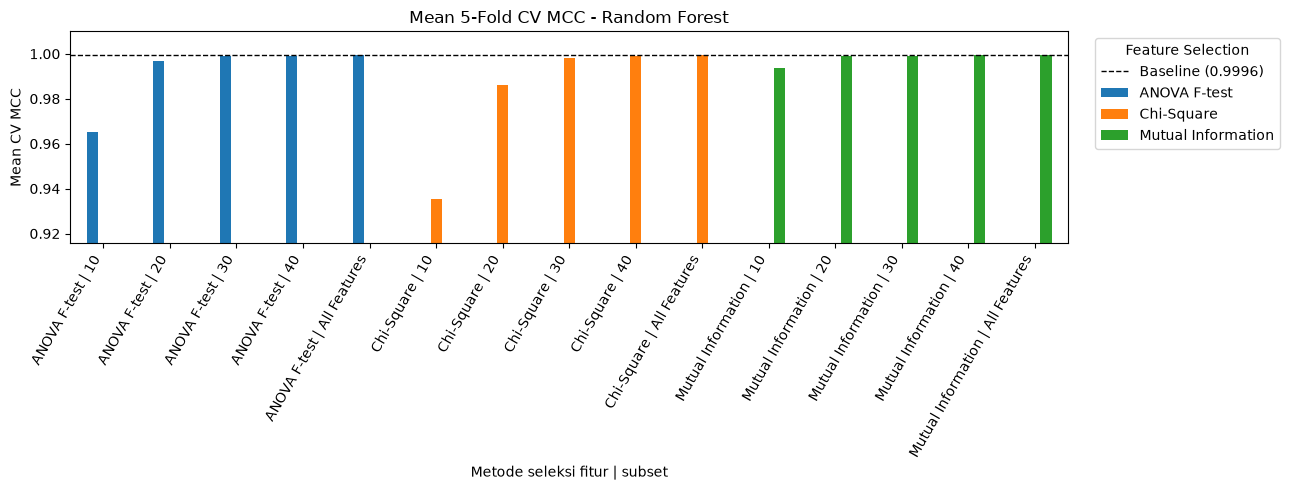

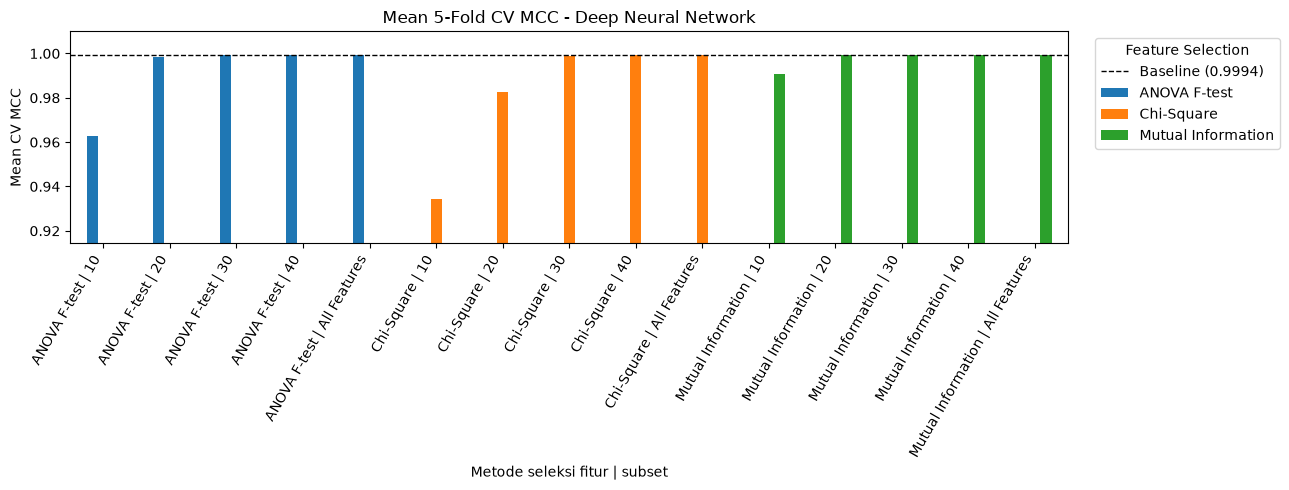

In [23]:
# Memvisualisasikan mean CV MCC per model, metode, dan subset fitur
plot_data = cv_summary[
    cv_summary["feature_selection"] != "No Feature Selection"
].copy()

plot_data["configuration"] = (
    plot_data["feature_selection"]
    + " | "
    + plot_data["subset"].astype(str)
)

for model_name in MODELS:
    part = plot_data[
        plot_data["model"] == model_name
    ].copy()

    pivot = part.pivot(
        index="configuration",
        columns="feature_selection",
        values="mcc_mean"
    )

    ax = pivot.plot(
        kind="bar",
        figsize=(13, 5)
    )

    ax.set_title(f"Mean 5-Fold CV MCC - {model_name}")
    ax.set_xlabel("Metode seleksi fitur | subset")
    ax.set_ylabel("Mean CV MCC")

    # Garis baseline (49 fitur, tanpa seleksi)
    base_mcc = baseline.loc[model_name, "mcc_mean"]
    ax.axhline(base_mcc, color="black", linestyle="--", linewidth=1, label=f"Baseline ({base_mcc:.4f})")

    # Menentukan batas sumbu Y
    y_min = max(0, float(pivot.min().min()) - 0.02)
    ax.set_ylim(y_min, 1.01)

    # Memiringkan label sumbu X tanpa plt.xticks()
    ax.tick_params(axis="x", labelrotation=60)

    for label in ax.get_xticklabels():
        label.set_horizontalalignment("right")

    ax.legend(
        title="Feature Selection",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()
    save_figure(ax.figure, f"fig2_cv_mcc_{model_name.lower().replace(' ', '_')}")
    plt.show()

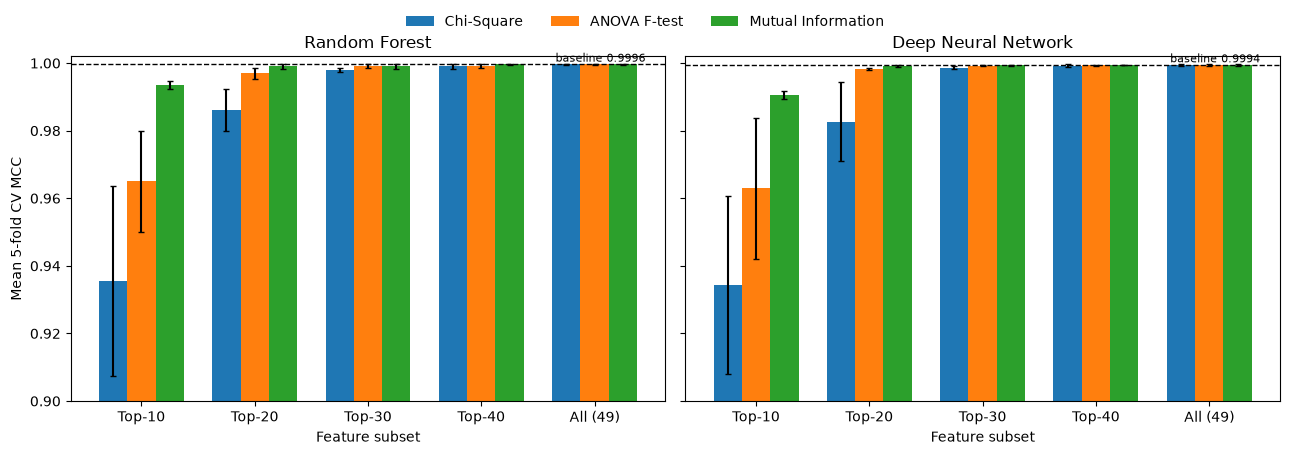

In [24]:
# Gambar 2 versi naskah: mean CV MCC per subset, dikelompokkan per metode, dengan garis baseline
order = ["10", "20", "30", "40", "All Features"]
labels = ["Top-10", "Top-20", "Top-30", "Top-40", "All (49)"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, model_name in zip(axes, ["Random Forest", "Deep Neural Network"]):
    part = cv_summary[(cv_summary["model"] == model_name) & (cv_summary["feature_selection"] != "No Feature Selection")]
    pivot = part.pivot(index="subset", columns="feature_selection", values="mcc_mean").loc[order, FEATURE_SELECTORS]
    err = part.pivot(index="subset", columns="feature_selection", values="mcc_std").loc[order, FEATURE_SELECTORS]
    pivot.index = labels
    err.index = labels
    pivot.plot(kind="bar", yerr=err, ax=ax, capsize=2, width=0.75, legend=False)
    base_mcc = baseline.loc[model_name, "mcc_mean"]
    ax.axhline(base_mcc, color="black", linestyle="--", linewidth=1)
    ax.text(4.45, base_mcc, f"baseline {base_mcc:.4f}", va="bottom", ha="right", fontsize=8)
    ax.set_title(model_name)
    ax.set_xlabel("Feature subset")
    ax.tick_params(axis="x", labelrotation=0)
    ax.set_ylim(0.90, 1.002)
axes[0].set_ylabel("Mean 5-fold CV MCC")
handles, names = axes[0].get_legend_handles_labels()
fig.legend(handles, names, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.04))
plt.tight_layout()
save_figure(fig, "fig2_cv_mcc_manuscript")
plt.show()

### 12.1 Performa pada Test Set

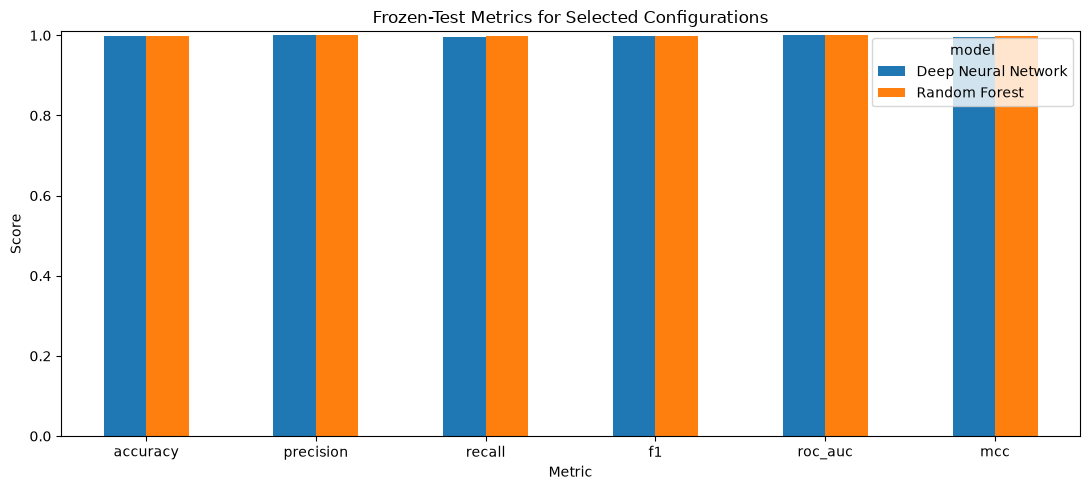

Deep Neural Network | No Feature Selection | All Features


,Predicted Legitimate,Predicted Phishing
Actual Legitimate,26968,2
Actual Phishing,95,20009


Random Forest | Mutual Information | 40


,Predicted Legitimate,Predicted Phishing
Actual Legitimate,26969,1
Actual Phishing,19,20085


Hasil tersimpan di: C:\Users\Alya Rafina\AppData\Local\Claude-Data\claude_pzs8sxrjxfjjc\scratch-workspaces\3c3e5256-8e66-42e1-ab9d-629398f109ce\0cff7c79-68ec-4344-aa0c-1c77d35a8517\scratch-2026-11-09-45d048\work\nb\hasil_phishing_sederhana


In [25]:
# Memvisualisasikan metrik test dan confusion matrix (konfigurasi terpilih)
selected_test = final_test_results[final_test_results["peran"].str.contains("terpilih")]
plot_metrics = ["accuracy", "precision", "recall", "f1", "roc_auc", "mcc"]
ax = selected_test.set_index("model")[plot_metrics].T.plot(kind="bar", figsize=(11, 5))
ax.set_title("Frozen-Test Metrics for Selected Configurations")
ax.set_xlabel("Metric")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.01)
plt.xticks(rotation=0)
plt.tight_layout()
save_figure(ax.figure, "fig3_test_metrics")
plt.show()

for _, row in selected_test.iterrows():
    cm = pd.DataFrame(
        [[row["TN"], row["FP"]], [row["FN"], row["TP"]]],
        index=["Actual Legitimate", "Actual Phishing"],
        columns=["Predicted Legitimate", "Predicted Phishing"]
    )
    print(f"{row['model']} | {row['feature_selection']} | {row['subset']}")
    display(cm)

print("Hasil tersimpan di:", OUTPUT_DIR.resolve())

## 13. Tabel Lengkap Hasil Cross-Validation

In [26]:
# Menampilkan dan menyimpan seluruh skor cross-validation
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

cv_scores_all = cv_summary.sort_values(
    ["model", "feature_selection", "subset"]
).reset_index(drop=True)

display(cv_scores_all)

# Simpan hasil lengkap
cv_scores_all.to_csv(
    OUTPUT_DIR / "cross_validation_scores_all_configurations.csv",
    index=False
)

,experiment,model,feature_selection,subset,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,specificity_mean,specificity_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,mcc_mean,mcc_std,balanced_accuracy_mean,balanced_accuracy_std,n_features,fit_time_s_mean,n_iter_mean
0,main,Deep Neural Network,ANOVA F-test,10,0.981795,0.010374,0.984361,0.003553,0.972853,0.025158,0.988459,0.002759,0.978430,0.012697,0.998747,0.000659,0.998370,0.000898,0.962937,0.020912,0.980656,0.012231,10,71.351314,28.6
1,main,Deep Neural Network,ANOVA F-test,20,0.999177,0.000155,0.999353,0.000168,0.998719,0.000385,0.999518,0.000125,0.999036,0.000182,0.999941,0.000059,0.999953,0.000040,0.998318,0.000316,0.999119,0.000181,20,41.828175,17.4
2,main,Deep Neural Network,ANOVA F-test,30,0.999644,0.000055,0.999851,0.000204,0.999316,0.000267,0.999889,0.000152,0.999583,0.000065,0.999986,0.000019,0.999987,0.000014,0.999273,0.000112,0.999602,0.000075,30,38.771615,15.0
3,main,Deep Neural Network,ANOVA F-test,40,0.999655,0.000094,0.999801,0.000111,0.999391,0.000155,0.999852,0.000083,0.999596,0.000110,0.999984,0.000015,0.999985,0.000012,0.999295,0.000192,0.999621,0.000100,40,37.058194,14.2
4,main,Deep Neural Network,ANOVA F-test,All Features,0.999724,0.000097,0.999826,0.000290,0.999527,0.000184,0.999870,0.000216,0.999677,0.000113,0.999991,0.000009,0.999991,0.000009,0.999436,0.000198,0.999699,0.000088,49,38.739415,13.8
5,main,Deep Neural Network,Chi-Square,10,0.967742,0.013160,0.970560,0.004370,0.953442,0.032831,0.978402,0.003620,0.961669,0.016590,0.996281,0.000790,0.994849,0.001169,0.934292,0.026431,0.965922,0.015634,10,52.336216,20.6
6,main,Deep Neural Network,Chi-Square,20,0.991513,0.005755,0.994136,0.000895,0.985948,0.013850,0.995662,0.000689,0.989984,0.006898,0.999632,0.000213,0.999548,0.000284,0.982708,0.011649,0.990805,0.006783,20,59.894888,23.6
7,main,Deep Neural Network,Chi-Square,30,0.999352,0.000157,0.999676,0.000135,0.998806,0.000364,0.999759,0.000100,0.999241,0.000184,0.999968,0.000027,0.999968,0.000023,0.998676,0.000320,0.999283,0.000181,30,38.502096,14.4
8,main,Deep Neural Network,Chi-Square,40,0.999623,0.000179,0.999714,0.000227,0.999403,0.000407,0.999787,0.000169,0.999558,0.000209,0.999983,0.000019,0.999986,0.000013,0.999230,0.000365,0.999595,0.000202,40,41.339234,15.4
9,main,Deep Neural Network,Chi-Square,All Features,0.999724,0.000097,0.999826,0.000290,0.999527,0.000184,0.999870,0.000216,0.999677,0.000113,0.999991,0.000009,0.999991,0.000009,0.999436,0.000198,0.999699,0.000088,49,38.739415,13.8


## 14. Confusion Matrix Konfigurasi Terpilih

In [27]:
# Menampilkan confusion matrix untuk seluruh model terpilih
for model_name, pipe in final_models.items():
    y_pred = pipe.predict(X_test_np)

    cm = confusion_matrix(
        y_test_np,
        y_pred,
        labels=[1, 0]
    )

    cm_df = pd.DataFrame(
        cm,
        index=["Actual Legitimate", "Actual Phishing"],
        columns=["Predicted Legitimate", "Predicted Phishing"]
    )

    print(f"\nConfusion Matrix - {model_name}")
    display(cm_df)


Confusion Matrix - Deep Neural Network


,Predicted Legitimate,Predicted Phishing
Actual Legitimate,26968,2
Actual Phishing,95,20009



Confusion Matrix - Random Forest


,Predicted Legitimate,Predicted Phishing
Actual Legitimate,26969,1
Actual Phishing,19,20085


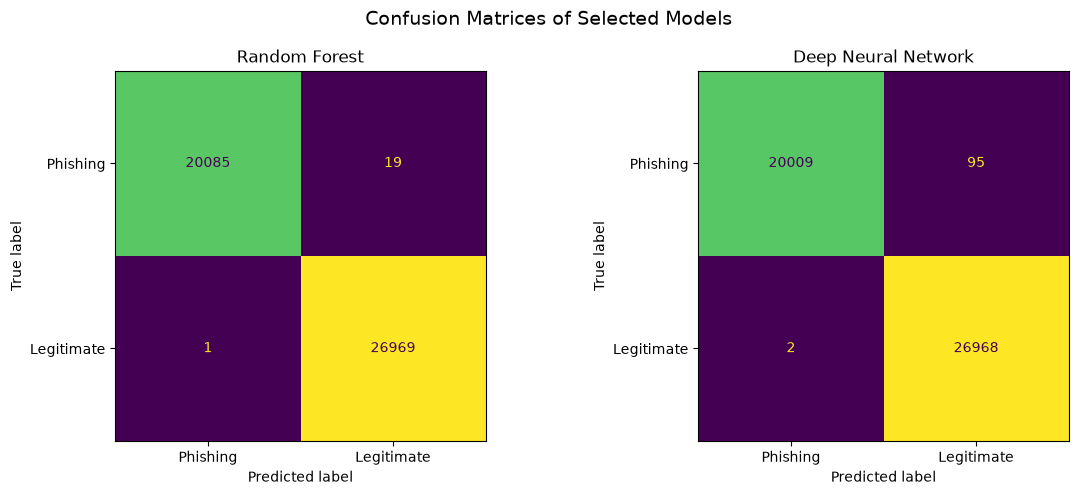

In [28]:
# Hitung confusion matrix
cm_rf = confusion_matrix(
    y_test_np,
    final_models["Random Forest"].predict(X_test_np),
    labels=[0, 1]
)

cm_dnn = confusion_matrix(
    y_test_np,
    final_models["Deep Neural Network"].predict(X_test_np),
    labels=[0, 1]
)

# Plot berdampingan
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

display_labels = ["Phishing", "Legitimate"]

ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=display_labels
).plot(ax=axes[0], values_format="d", colorbar=False)

axes[0].set_title("Random Forest")

ConfusionMatrixDisplay(
    confusion_matrix=cm_dnn,
    display_labels=display_labels
).plot(ax=axes[1], values_format="d", colorbar=False)

axes[1].set_title("Deep Neural Network")

fig.suptitle("Confusion Matrices of Selected Models", fontsize=14)
plt.tight_layout()
save_figure(fig, "fig4_confusion_matrices")
plt.show()

## 15. Analisis Ranking Fitur

Skor fitur dihitung menggunakan seluruh data training dengan preprocessing yang sama dengan pipeline (imputasi median → MinMaxScaler). Mutual Information memakai mask discrete fitur biner dan `n_neighbors=3`. Ranking lengkap 49 fitur untuk ketiga metode disimpan ke `feature_ranking_full_training.csv`.

In [29]:
# Menghitung ranking fitur menggunakan data training
chi2_scores = ScoreFunction("Chi-Square", FEATURE_NAMES)(X_train_prep, y_train_np)
anova_scores = ScoreFunction("ANOVA F-test", FEATURE_NAMES)(X_train_prep, y_train_np)
mi_scores = ScoreFunction("Mutual Information", FEATURE_NAMES)(X_train_prep, y_train_np)

def ranking_table(scores, top=10):
    table = pd.DataFrame({
        "Feature": FEATURE_NAMES,
        "Score": scores
    }).sort_values("Score", ascending=False).head(top).reset_index(drop=True)
    table.index = table.index + 1
    table.index.name = "Rank"
    return table

chi2_ranking = ranking_table(chi2_scores)
anova_ranking = ranking_table(anova_scores)
mi_ranking = ranking_table(mi_scores)

print("Top-10 Features - Chi-Square")
display(chi2_ranking)
print("Top-10 Features - ANOVA F-test")
display(anova_ranking)
print("Top-10 Features - Mutual Information")
display(mi_ranking)

full_ranking = pd.DataFrame({"rank": range(1, len(FEATURE_NAMES) + 1)})
for name, scores in [("Chi-Square", chi2_scores), ("ANOVA F-test", anova_scores), ("Mutual Information", mi_scores)]:
    order = pd.Series(scores, index=FEATURE_NAMES).sort_values(ascending=False)
    full_ranking[name] = order.index
    full_ranking[f"{name} score"] = order.values
full_ranking.to_csv(OUTPUT_DIR / "feature_ranking_full_training.csv", index=False)

# Irisan Top-k antarmetode
overlap_rows = []
for k in [10, 20, 30, 40]:
    tops = {n: set(full_ranking[n].head(k)) for n in FEATURE_SELECTORS}
    overlap_rows.append({
        "k": k,
        "Chi2∩ANOVA": len(tops["Chi-Square"] & tops["ANOVA F-test"]),
        "Chi2∩MI": len(tops["Chi-Square"] & tops["Mutual Information"]),
        "ANOVA∩MI": len(tops["ANOVA F-test"] & tops["Mutual Information"]),
        "ketiganya": len(tops["Chi-Square"] & tops["ANOVA F-test"] & tops["Mutual Information"]),
    })
ranking_overlap = pd.DataFrame(overlap_rows)
display(ranking_overlap)
ranking_overlap.to_csv(OUTPUT_DIR / "ranking_overlap_between_filters.csv", index=False)

# Komposisi jenis fitur pada Top-k
composition = pd.DataFrame([
    {"metode": n, "k": k, **pd.Series([FEATURE_KIND[f] for f in full_ranking[n].head(k)]).value_counts().to_dict()}
    for n in FEATURE_SELECTORS for k in [10, 20]
]).fillna(0)
display(composition)
composition.to_csv(OUTPUT_DIR / "topk_composition_by_type.csv", index=False)

Top-10 Features - Chi-Square


,Feature,Score
Rank,,
1,HasSocialNet,62936.969412
2,HasCopyrightInfo,53619.790904
3,HasDescription,50043.631690
4,HasSubmitButton,37320.267311
5,DomainTitleMatchScore,31683.879536
6,HasHiddenFields,28803.361634
7,HasFavicon,28369.201841
8,URLTitleMatchScore,25445.287073
9,Robots,21095.860812


Top-10 Features - ANOVA F-test


,Feature,Score
Rank,,
1,HasSocialNet,301642.896936
2,HasCopyrightInfo,234605.224897
3,HasDescription,170762.630107
4,IsHTTPS,106869.417630
5,DomainTitleMatchScore,97970.135490
6,HasSubmitButton,96267.081474
7,URLTitleMatchScore,75997.173792
8,IsResponsive,74889.147772
9,SpacialCharRatioInURL,74600.083095


Top-10 Features - Mutual Information


,Feature,Score
Rank,,
1,LineOfCode,0.601551
2,NoOfExternalRef,0.564428
3,NoOfImage,0.547163
4,NoOfSelfRef,0.528408
5,NoOfJS,0.496887
6,LargestLineLength,0.489933
7,NoOfCSS,0.443765
8,HasSocialNet,0.386503
9,LetterRatioInURL,0.378645


,k,Chi2∩ANOVA,Chi2∩MI,ANOVA∩MI,ketiganya
0,10,8,2,2,2
1,20,16,9,12,9
2,30,21,18,26,17
3,40,38,34,36,34


,metode,k,binary,continuous,integer
0,Chi-Square,10,8,2,0.0
1,Chi-Square,20,15,5,0.0
2,ANOVA F-test,10,7,3,0.0
3,ANOVA F-test,20,11,7,2.0
4,Mutual Information,10,2,1,7.0
5,Mutual Information,20,5,6,9.0


### 15.1 Visualisasi Top-10 Fitur

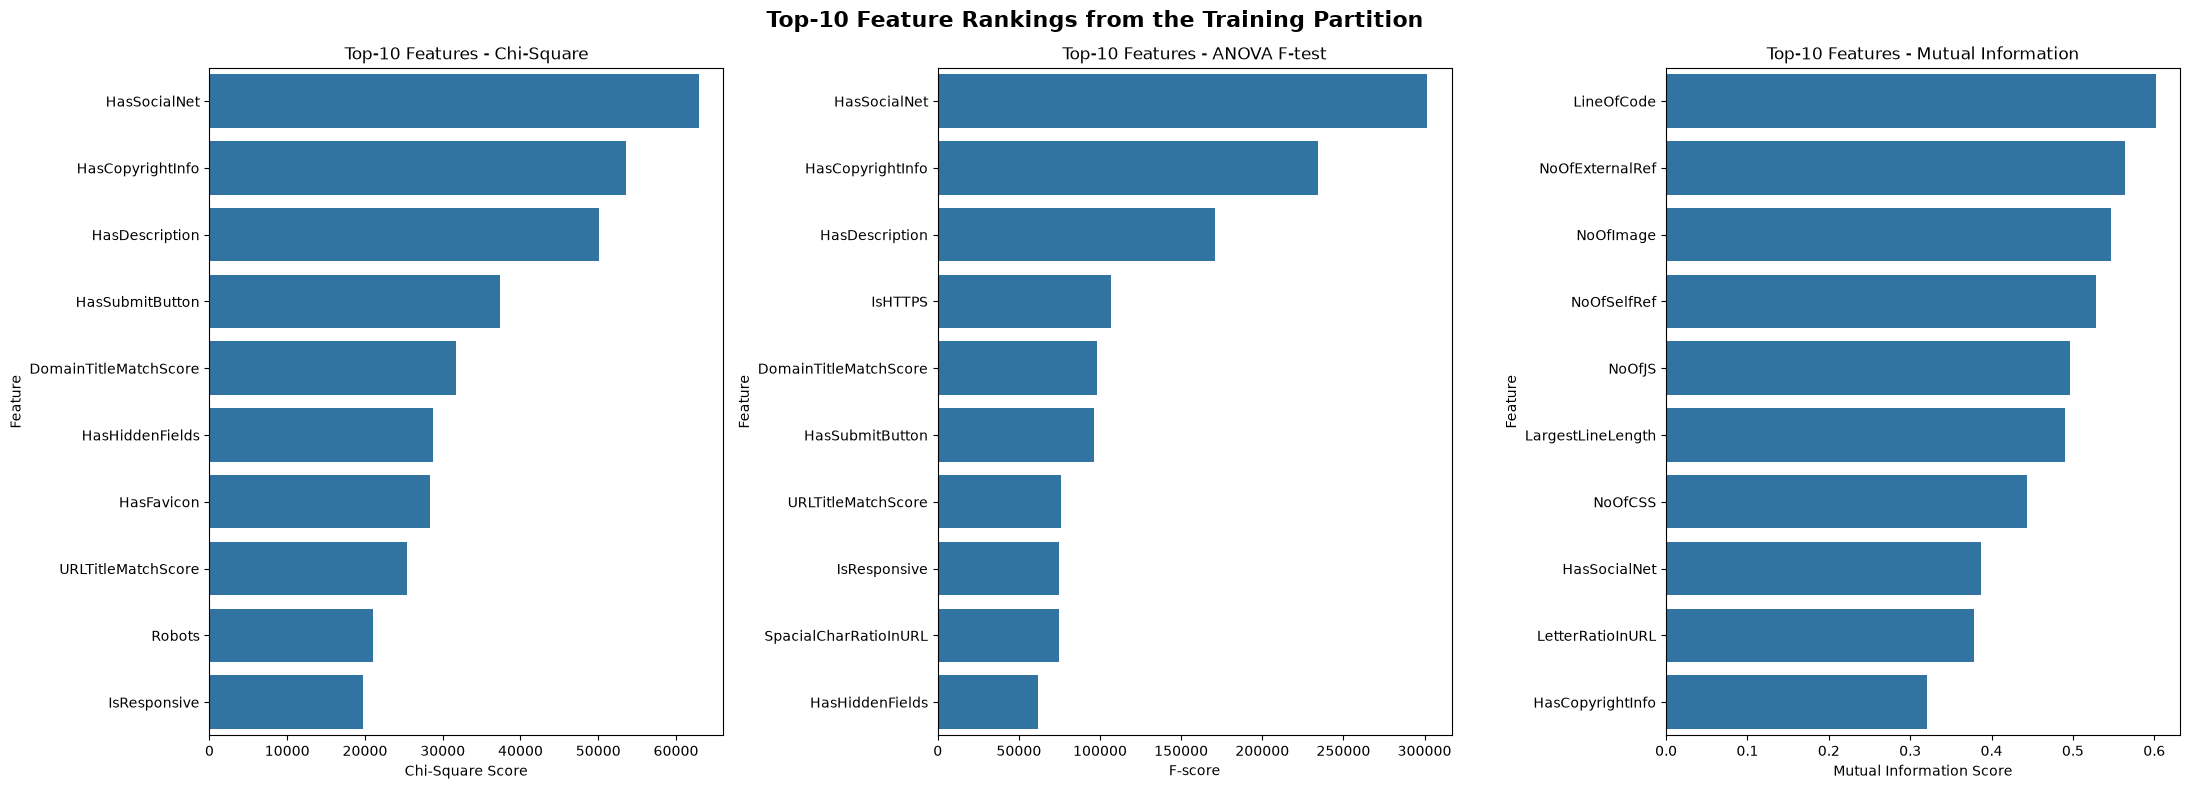

In [30]:
# Memvisualisasikan ranking Top-10 fitur
fig, axes = plt.subplots(1, 3, figsize=(22, 8))

sns.barplot(
    data=chi2_ranking,
    x="Score",
    y="Feature",
    ax=axes[0]
)
axes[0].set_title("Top-10 Features - Chi-Square")
axes[0].set_xlabel("Chi-Square Score")
axes[0].set_ylabel("Feature")

sns.barplot(
    data=anova_ranking,
    x="Score",
    y="Feature",
    ax=axes[1]
)
axes[1].set_title("Top-10 Features - ANOVA F-test")
axes[1].set_xlabel("F-score")
axes[1].set_ylabel("Feature")

sns.barplot(
    data=mi_ranking,
    x="Score",
    y="Feature",
    ax=axes[2]
)
axes[2].set_title("Top-10 Features - Mutual Information")
axes[2].set_xlabel("Mutual Information Score")
axes[2].set_ylabel("Feature")

plt.suptitle(
    "Top-10 Feature Rankings from the Training Partition",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
save_figure(fig, "fig5_top10_feature_rankings")
plt.show()

## 16. Pemeriksaan Konfigurasi Terpilih

In [ ]:
print("Jumlah konfigurasi:", len(selected_configs))
print(selected_configs[["model", "feature_selection", "subset", "n_features"]])

key_numbers = {
    "environment": environment,
    "feature_accounting": feature_accounting.to_dict("records"),
    "groups": group_summary.to_dict("records"),
    "legacy_split_audit": legacy_audit.to_dict("records"),
    "split": split_summary.to_dict("records"),
    "folds": fold_table.to_dict("records"),
    "selected_configs": selected_configs[["model", "feature_selection", "subset", "n_features", "mcc_mean", "mcc_std"]].to_dict("records"),
    "best_reduced": cv_comparison.to_dict("records"),
    "final_test": final_test_results.drop(columns=[]).to_dict("records"),
    "efficiency": computational_efficiency.to_dict("records"),
}
(OUTPUT_DIR / "key_numbers.json").write_text(json.dumps(key_numbers, indent=2, default=str))

Jumlah konfigurasi: 2
                 model     feature_selection        subset  n_features
0  Deep Neural Network  No Feature Selection  All Features          49
1        Random Forest    Mutual Information            40          40


9824

# Analisis

### 1. Performa Model (pemilihan dari 5-fold CV berbasis domain induk)

| **Tahap** | **Random Forest** | **Deep Neural Network** |
|---|---:|---:|
| Baseline 49 fitur (5-fold CV) | MCC: 0.999620 ± 0.000172 | MCC: 0.999436 ± 0.000198 |
| Konfigurasi terpilih (5-fold CV) | MI Top-40 — MCC: 0.999664 ± 0.000169 | Tanpa seleksi (49 fitur) — MCC: 0.999436 ± 0.000198 |
| MCC frozen test (seed 42) | 0.999132 | 0.995795 |
| MCC frozen test, 6 seed (mean ± SD) | 0.999407 ± 0.000195 | 0.998229 ± 0.001695 |

Random Forest terbaik memakai Mutual Information Top-40; DNN terbaik justru baseline tanpa seleksi. Hasil test DNN sangat bergantung pada seed: dua dari enam seed meloloskan 79 dan 95 URL phishing, sedangkan seed lain hanya 8–17. DNN MI Top-40 (referensi, tidak dipilih) lebih stabil (0.999132–0.999566).

### 2. Dataset dan pemisahan domain

Dari 55 kolom: label dipisah (54), empat kolom dikecualikan (50), dan `TLD` tersaring oleh `select_dtypes` sehingga tersisa 49 prediktor. Grup memakai domain induk (eTLD+1, 175.514 grup). Split versi sebelumnya (grup netloc, 219.102 grup) masih memiliki 1.549 domain induk di train dan test (23,5% baris test); split revisi tidak memiliki overlap. Validasi internal early stopping DNN tetap per baris (15%, accuracy) sehingga tidak semua tahap validasi berbasis domain.

### 3. Pengaruh seleksi fitur

Dengan input classifier yang seragam, konfigurasi All Features identik dengan baseline sehingga tidak dihitung sebagai efek seleksi. Seleksi fitur **tidak meningkatkan MCC secara berarti**: RF MI Top-40 hanya +0.000043 di atas baseline (unggul di 4 dari 5 fold), DNN MI Top-40 setara baseline. Perbedaan metode terlihat jelas saat reduksi kuat: Top-10 MI 0.9935 (RF) / 0.9905 (DNN), ANOVA 0.9650 / 0.9629, Chi-Square 0.9356 / 0.9343.

### 4. Ranking fitur dan audit

Chi-Square dan ANOVA mengutamakan indikator biner (`HasSocialNet`, `HasCopyrightInfo`, `HasDescription`); MI mengutamakan hitungan struktur halaman (`LineOfCode`, `NoOfExternalRef`, `NoOfImage`). Fitur-fitur hitungan ini juga yang terkuat secara univariat (MCC stump 0.88–0.91), tetapi tidak ada yang mendekati `URLSimilarityIndex` (0.993) yang dikecualikan.

### 5. Sensitivitas

* Pengaturan MI (auto, biner, integer, n_neighbors 3/5/10): Top-10 dan Top-20 identik; konfigurasi terpilih tidak berubah.
* Tanpa `TLDLegitimateProb` dan `URLCharProb`: perubahan mean CV MCC ≤ 0.000054.
* Early stopping berbasis grup domain (MCC): perubahan −0.000152 s.d. −0.000119.

### 6. Hasil terukur vs hipotesis

* **Terukur:** skor CV dan test, variasi antar-seed, waktu pelatihan/inferensi, ukuran model, audit dan sensitivitas di atas.
* **Hipotesis :** MI lebih unggul karena menangkap ketergantungan non-linear fitur hitungan; pengurangan fitur lemah menstabilkan pelatihan DNN.
* **Efisiensi:** waktu CV RF turun seiring berkurangnya fitur, tetapi refit tunggal subset 40 fitur tidak menunjukkan penghematan konsisten. Manfaat efisiensi masih berupa potensi.

### 7. Keterbatasan dan saran

* Hanya satu dataset (PhiUSIIL); banyak fitur terkuat membutuhkan akses halaman web.
* Hiperparameter tetap, tidak ada uji statistik, dan pengukuran waktu hanya satu kali pada satu mesin.
* Saran: uji lintas dataset, data phishing terbaru dan terpisah waktu, fitur URL-only, CV berulang dengan uji statistik, dan pengukuran efisiensi yang sistematis.